# **LAB04: Mạng nơ-ron nhiều lớp (MLP) và nhận dạng chữ số viết tay MNIST**

> **Họ tên: Vương Thành Đạt - MSSV: 24280058**


## **Quy tắc "From Scratch"**

Thư viện PyTorch chỉ được dùng để **chứa tham số và tính lan truyền thuận (forward pass)**. Mọi tính toán liên quan tới **gradient, lan truyền ngược (backward pass), và cập nhật trọng số** đều phải được tự cài đặt từ đầu.

| Thành phần được dùng thư viện | Thành phần tự cài đặt (From Scratch) |
|---|---|
| `nn.Linear`, `nn.Sequential`, các module kích hoạt khi forward | Toàn bộ backward: BP1 đến BP4, đạo hàm ReLU, Sigmoid, Tanh, $\boldsymbol{\Delta}^{(L)}$ của Softmax + Cross-Entropy |
| `nn.init` (Xavier, He) | Bộ tối ưu SGD + Momentum ($\Delta \mathbf{w}$ theo công thức quán tính) |
| `torchvision` để tải MNIST | Inverted Dropout (cả chiều forward và backward), số hạng L2 Regularization (Weight Decay) trong gradient |
| Autograd và `torch.optim` (**chỉ** trong ô kiểm chứng 3.1) | Vòng lặp huấn luyện mini-batch, cơ chế Early Stopping |

Tuyệt đối không sử dụng `loss.backward()`, `torch.autograd`, `torch.optim` trong các phần cài đặt thuật toán.

---
## **Phần 0: Chuẩn bị thư viện và dữ liệu**

### **0.1. Chuẩn bị thư viện và thiết lập môi trường**
Để đảm bảo quy tắc "from scratch", ta gọi lệnh `torch.set_grad_enabled(False)` ngay từ đầu. Khi autograd bị vô hiệu hoá, mọi lời gọi vô tình tới `loss.backward()` sẽ lập tức báo lỗi. Cố định `SEED = 42` để đảm bảo tính tái lập của mọi thử nghiệm.

In [1]:
!pip install torch torchvision

import os, gzip, shutil, time, copy, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Tắt autograd cho toàn bộ notebook: gradient hoàn toàn do ta tự tính
torch.set_grad_enabled(False)

print("PyTorch Version:", torch.__version__, "| Số lượng CPU threads:", torch.get_num_threads())


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


PyTorch Version: 2.14.1+cpu | Số lượng CPU threads: 8


### **0.2. Tải dữ liệu MNIST**
Hàm `load_mnist` tải dữ liệu qua `torchvision.datasets.MNIST`. Nếu nguồn mặc định gặp sự cố kết nối, hàm sẽ tự động chuyển sang mirror lưu trữ trên GitHub để đảm bảo quá trình tải dữ liệu luôn thông suốt.

In [2]:
DATA_ROOT = "./data"
MNIST_FILES = ["train-images-idx3-ubyte", "train-labels-idx1-ubyte",
               "t10k-images-idx3-ubyte", "t10k-labels-idx1-ubyte"]
GITHUB_MIRROR = "https://raw.githubusercontent.com/fgnt/mnist/master/"


def _download_from_mirror(root):
    raw = os.path.join(root, "MNIST", "raw")
    os.makedirs(raw, exist_ok=True)
    for name in MNIST_FILES:
        dst = os.path.join(raw, name)
        if os.path.exists(dst):
            continue
        gz = dst + ".gz"
        urllib.request.urlretrieve(GITHUB_MIRROR + name + ".gz", gz)
        with gzip.open(gz, "rb") as f_in, open(dst, "wb") as f_out:
            shutil.copyfileobj(f_in, f_out)


def load_mnist(root=DATA_ROOT):
    try:
        train = torchvision.datasets.MNIST(root, train=True, download=True)
        test = torchvision.datasets.MNIST(root, train=False, download=True)
    except Exception as e:
        print("Nguồn mặc định của torchvision lỗi (", type(e).__name__, "), chuyển sang mirror GitHub")
        _download_from_mirror(root)
        train = torchvision.datasets.MNIST(root, train=True, download=False)
        test = torchvision.datasets.MNIST(root, train=False, download=False)
    return train.data, train.targets, test.data, test.targets


Xtr_raw, ytr_raw, Xte_raw, yte_raw = load_mnist()
print("Dữ liệu thô - Train:", tuple(Xtr_raw.shape), "| Test:", tuple(Xte_raw.shape))

Dữ liệu thô - Train: (60000, 28, 28) | Test: (10000, 28, 28)


### **0.3. Giới thiệu và khám phá tổng quan bộ dữ liệu MNIST ban đầu**

Bộ dữ liệu **MNIST (Modified National Institute of Standards and Technology)** là bộ dữ liệu kinh điển trong thị giác máy tính và nhận dạng mẫu:
* **Nguồn gốc:** Do Yann LeCun, Corinna Cortes và Christopher Burges tạo ra từ hai tập dữ liệu của Viện Tiêu chuẩn và Kỹ thuật Quốc gia Hoa Kỳ (NIST), gồm chữ số viết tay của học sinh trung học và nhân viên Cục Điều tra Dân số Hoa Kỳ.
* **Quy mô:** Gồm **70.000 ảnh** chữ số viết tay chia thành **60.000 ảnh huấn luyện** và **10.000 ảnh kiểm tra**.
* **Định dạng ảnh:** Mỗi mẫu là một ảnh xám (grayscale) đơn kênh kích thước **28 × 28 pixel**, đã được căn giữa (centered) theo trọng tâm điểm ảnh.
* **Cường độ điểm ảnh:** Mỗi pixel có giá trị là số nguyên không âm trong đoạn $[0, 255]$:
  * $0$: Nền đen (không có mực).
  * $255$: Nét chữ màu trắng (độ đậm mực tối đa).
* **Nhãn lớp:** Các số nguyên từ $0$ đến $9$, tương ứng với 10 chữ số trong hệ thập phân.

In [3]:
# Kiểm tra kiểu dữ liệu, kích thước và miền giá trị của bộ dữ liệu MNIST thô
print("Kiểu dữ liệu của Xtr_raw:      ", type(Xtr_raw))
print("Kiểu dữ liệu của ytr_raw:      ", type(ytr_raw))
print("Kích thước tập ảnh train (raw):", Xtr_raw.shape)
print("Kích thước tập nhãn train (raw):", ytr_raw.shape)
print("Kiểu phần tử (dtype) của ảnh:  ", Xtr_raw.dtype)
print("Kiểu phần tử (dtype) của nhãn: ", ytr_raw.dtype)
print(f"Miền giá trị pixel: [min = {Xtr_raw.min().item()}, max = {Xtr_raw.max().item()}]")
print("Danh sách các lớp nhãn (0-9):  ", torch.unique(ytr_raw).tolist())
print(f"Số lượng mẫu mỗi lớp (train):   {torch.bincount(ytr_raw).tolist()}")

Kiểu dữ liệu của Xtr_raw:       <class 'torch.Tensor'>
Kiểu dữ liệu của ytr_raw:       <class 'torch.Tensor'>
Kích thước tập ảnh train (raw): torch.Size([60000, 28, 28])
Kích thước tập nhãn train (raw): torch.Size([60000])
Kiểu phần tử (dtype) của ảnh:   torch.uint8
Kiểu phần tử (dtype) của nhãn:  torch.int64
Miền giá trị pixel: [min = 0, max = 255]
Danh sách các lớp nhãn (0-9):   [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Số lượng mẫu mỗi lớp (train):   [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


### **0.4. Phân chia dữ liệu và Chuẩn hoá (Tiền xử lý)**

**1. Phân chia tập dữ liệu:**
* 60.000 ảnh huấn luyện ban đầu được chia ngẫu nhiên thành **50.000 ảnh train** (dùng huấn luyện mô hình) và **10.000 ảnh validation** (dùng tinh chỉnh siêu tham số và early stopping).
* Tập **test** gồm 10.000 ảnh được giữ nguyên vẹn và **chỉ được đánh giá đúng một lần duy nhất** ở Phần 7 để đo lường năng lực tổng quát hoá thực tế của mô hình.

**2. Bản chất toán học của tiền xử lý (Z-score Standardization):**
Mỗi ảnh $28 \times 28$ được duỗi phẳng thành một vector đặc trưng $\mathbf{x} \in \mathbb{R}^{784}$ ($784 = 28 \times 28$).
Sau đó, các giá trị pixel được chia cho 255 để đưa về đoạn $[0, 1]$ và chuẩn hoá theo công thức Z-score:
$$x_{\text{norm}} = \frac{x / 255.0 - \mu_{\text{train}}}{\sigma_{\text{train}}}$$
Trong đó $\mu_{\text{train}}$ và $\sigma_{\text{train}}$ là giá trị trung bình và độ lệch chuẩn được tính **chỉ trên 50.000 ảnh của tập train**.
* **Nguyên tắc chống rò rỉ dữ liệu (No Data Leakage):** Tuyệt đối không dùng thông tin thống kê của tập validation hay test khi chuẩn hoá, nhằm phản ánh chính xác bài toán thực tế khi mô hình gặp các mẫu dữ liệu mới chưa từng biết.

In [4]:
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(Xtr_raw), generator=g)
tr_idx, va_idx = perm[:50000], perm[50000:]

_X = Xtr_raw[tr_idx].reshape(-1, 784).float() / 255.0
MEAN, STD = _X.mean().item(), _X.std().item()


def preprocess(X_raw):
    """Duỗi phẳng ảnh thành vector 784 chiều, đưa về [0, 1] và chuẩn hoá Z-score theo MEAN, STD của train."""
    return (X_raw.reshape(-1, 784).float() / 255.0 - MEAN) / STD


X_train, y_train = preprocess(Xtr_raw[tr_idx]), ytr_raw[tr_idx]
X_val, y_val = preprocess(Xtr_raw[va_idx]), ytr_raw[va_idx]
X_test, y_test = preprocess(Xte_raw), yte_raw

print(f"Giá trị thống kê tập train: MEAN = {MEAN:.4f}, STD = {STD:.4f}")
print("Kích thước sau tiền xử lý:")
print("  X_train:", tuple(X_train.shape), "| y_train:", tuple(y_train.shape))
print("  X_val:  ", tuple(X_val.shape), "  | y_val:  ", tuple(y_val.shape))
print("  X_test: ", tuple(X_test.shape), "  | y_test: ", tuple(y_test.shape))
print("Phân bố số mẫu mỗi lớp trên tập train (50.000 mẫu):", torch.bincount(y_train).tolist())

Giá trị thống kê tập train: MEAN = 0.1307, STD = 0.3082
Kích thước sau tiền xử lý:
  X_train: (50000, 784) | y_train: (50000,)
  X_val:   (10000, 784)   | y_val:   (10000,)
  X_test:  (10000, 784)   | y_test:  (10000,)
Phân bố số mẫu mỗi lớp trên tập train (50.000 mẫu): [4923, 5613, 4958, 5093, 4863, 4546, 4933, 5204, 4882, 4985]


### **0.5. Các hàm tiện ích trực quan hoá dữ liệu**
Để phục vụ việc quan sát xuyên suốt notebook, ta định nghĩa các hàm vẽ biểu đồ:
* `show_images`: Khôi phục ảnh từ vector chuẩn hoá về giá trị gốc và hiển thị lưới ảnh trực quan.
* `plot_history`: Vẽ đường cong suy giảm mất mát (Loss) và độ chính xác (Accuracy) trên train/val theo từng epoch.
* `plot_heatmap`: Trực quan hoá ma trận số liệu 2D dưới dạng bản đồ nhiệt (Heatmap).

In [5]:
def show_images(X, titles, n_cols=10, size=1.4):
    """Hiển thị lưới ảnh chữ số viết tay khôi phục về miền ảnh gốc."""
    n = len(X)
    n_rows = int(np.ceil(n / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(size * n_cols, size * 1.25 * n_rows))
    for ax in np.array(axes).reshape(-1):
        ax.axis("off")
    for k in range(n):
        ax = np.array(axes).reshape(-1)[k]
        ax.imshow((X[k] * STD + MEAN).reshape(28, 28), cmap="gray_r")
        ax.set_title(titles[k], fontsize=9)
    plt.tight_layout()
    plt.show()


def plot_history(histories, title=""):
    """Vẽ biểu đồ Loss và Accuracy qua các epoch (nét liền: train, nét đứt: val)."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for name, h in histories.items():
        ep = np.arange(1, len(h["val_loss"]) + 1)
        line, = axes[0].plot(ep, h["train_loss"], "-", label=f"{name} (train)")
        axes[0].plot(ep, h["val_loss"], "--", color=line.get_color(), label=f"{name} (val)")
        axes[1].plot(ep, h["train_acc"], "-", color=line.get_color())
        axes[1].plot(ep, h["val_acc"], "--", color=line.get_color())
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
    axes[0].legend(fontsize=8)
    axes[1].set_title("Nét liền: train, nét đứt: val", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_heatmap(M, row_labels, col_labels, row_name, col_name, title, cell_note=None):
    """Vẽ bản đồ nhiệt (Heatmap) biểu diễn giá trị của ma trận M."""
    fig, ax = plt.subplots(figsize=(1.6 * len(col_labels) + 2, 0.9 * len(row_labels) + 1.5))
    ax.imshow(np.nan_to_num(M, nan=np.nanmin(M) if np.isfinite(M).any() else 0), cmap="viridis")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            txt = "phân kỳ" if np.isnan(M[i, j]) else f"{M[i, j]:.4f}"
            if cell_note is not None:
                txt += "\n" + cell_note(i, j)
            ax.text(j, i, txt, ha="center", va="center", fontsize=8,
                    color="white" if np.isnan(M[i, j]) or M[i, j] < np.nanmedian(M) else "black")
    ax.set_xticks(range(len(col_labels))); ax.set_xticklabels(col_labels)
    ax.set_yticks(range(len(row_labels))); ax.set_yticklabels(row_labels)
    ax.set_xlabel(col_name); ax.set_ylabel(row_name); ax.set_title(title)
    plt.tight_layout()
    plt.show()

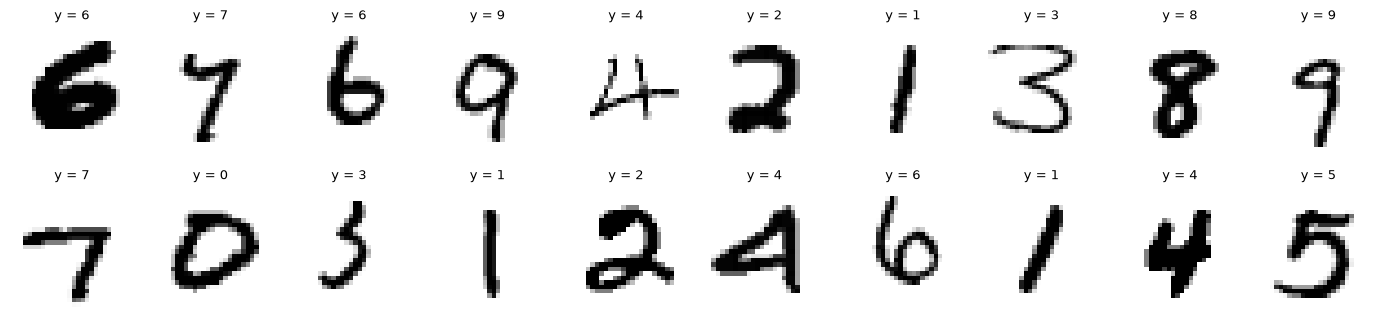

In [6]:
# Hiển thị trực quan 20 ảnh đầu tiên từ tập huấn luyện đã tiền xử lý
show_images(X_train[:20], [f"y = {int(t)}" for t in y_train[:20]])

---
## **Phần 1: Thiết kế mạng và lan truyền thuận (Forward Pass)**

### **1.1. Bản chất toán học của Lan truyền thuận dạng Ma trận (Vectorization)**

**1. Ký hiệu toán học thống nhất:**
* $L$: Tổng số lớp có trọng số trong mạng nơ-ron.
* $k_l$: Số lượng nơ-ron ở lớp $l$ (với $k_0 = 784$ là số đặc trưng đầu vào, $k_L = 10$ là số lớp đầu ra).
* $\mathbf{W}^{(l)} \in \mathbb{R}^{k_l \times k_{l-1}}$: Ma trận trọng số kết nối từ lớp $l-1$ sang lớp $l$.
* $\mathbf{b}^{(l)} \in \mathbb{R}^{k_l}$: Vector độ lệch (bias) của lớp $l$.
* $\mathbf{z}^{(l)}$: Tín hiệu trước kích hoạt (pre-activation).
* $\mathbf{a}^{(l)} = f(\mathbf{z}^{(l)})$: Tín hiệu sau kích hoạt (activation), với quy ước $\mathbf{a}^{(0)} = \mathbf{x}$.

**2. Xử lý theo mini-batch (Vectorization):**
Thay vì duyệt vòng lặp qua từng mẫu đơn lẻ gây lãng phí tài nguyên CPU, ta xếp $N$ mẫu dữ liệu thành các hàng của ma trận $\mathbf{A}^{(l-1)} \in \mathbb{R}^{N \times k_{l-1}}$. Toàn bộ quá trình biến đổi tuyến tính và phi tuyến của lớp $l$ được thực hiện đồng thời bằng phép nhân ma trận:
$$\mathbf{Z}^{(l)} = \mathbf{A}^{(l-1)} \big(\mathbf{W}^{(l)}\big)^{\top} + \mathbf{b}^{(l)} \in \mathbb{R}^{N \times k_l}$$
$$\mathbf{A}^{(l)} = f\big(\mathbf{Z}^{(l)}\big) \in \mathbb{R}^{N \times k_l}, \qquad \mathbf{A}^{(0)} = \mathbf{X}$$

* **Lưu ý về kích thước của `nn.Linear`:** Lớp `nn.Linear(k_in, k_out)` trong PyTorch lưu thuộc tính `weight` có kích thước đúng bằng $k_l \times k_{l-1}$ (tức $k_{\text{out}} \times k_{\text{in}}$). Phép toán `layer(A)` thực chất thực hiện $\mathbf{A} \mathbf{W}^{\top} + \mathbf{b}$ nhờ thư viện đại số tuyến tính BLAS tối ưu hoá cao độ.

**Hàm xây dựng mô hình MLP (`build_mlp`):**
Hàm này nhận danh sách kích thước các tầng `sizes = [784, k_1, ..., 10]`, hàm kích hoạt `activation`, tỷ lệ dropout `p_drop`, và phương pháp khởi tạo `init`:
* **Khởi tạo Kaiming He (cho ReLU):** $\text{std} = \sqrt{2 / k_{\text{in}}}$, bù đắp phương sai bị suy giảm khi ReLU dập tắt các giá trị âm.
* **Khởi tạo Xavier / Glorot (cho Sigmoid/Tanh):** Phân phối đều $\mathcal{U}\left(-\sqrt{\frac{6}{k_{\text{in}} + k_{\text{out}}}}, +\sqrt{\frac{6}{k_{\text{in}} + k_{\text{out}}}}\right)$, giữ phương sai tín hiệu ổn định qua các tầng.

In [7]:
ACTIVATIONS = {"relu": nn.ReLU, "sigmoid": nn.Sigmoid, "tanh": nn.Tanh}


def build_mlp(sizes, activation="relu", p_drop=0.0, init="he", const=0.01, seed=SEED):
    """sizes = [784, k_1, ..., k_{L-1}, 10]. Trả về nn.Sequential:
    Linear -> Act -> (Dropout) -> ... -> Linear (lớp ra không có hàm kích hoạt)."""
    torch.manual_seed(seed)
    layers = []
    L = len(sizes) - 1
    for l in range(L):
        lin = nn.Linear(sizes[l], sizes[l + 1])
        if init == "he":
            nn.init.kaiming_normal_(lin.weight, nonlinearity="relu")   # std = sqrt(2 / k_in)
        elif init == "xavier":
            nn.init.xavier_uniform_(lin.weight)                         # U(-sqrt(6/(k_in+k_out)), +...)
        elif init == "const":
            nn.init.constant_(lin.weight, const)                        # dùng để minh hoạ tính đối xứng
        else:
            raise ValueError(init)
        nn.init.zeros_(lin.bias)
        layers.append(lin)
        if l < L - 1:
            layers.append(ACTIVATIONS[activation]())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
    return nn.Sequential(*layers)


def n_params(model):
    """Tính tổng số lượng tham số học được (weights + biases) của mô hình."""
    return sum(p.numel() for p in model.parameters())


demo = build_mlp([784, 256, 128, 10], p_drop=0.2)
print("Kiến trúc mô hình minh hoạ:")
print(demo)
print("Tổng số tham số:", n_params(demo))

Kiến trúc mô hình minh hoạ:
Sequential(
  (0): Linear(in_features=784, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.2, inplace=False)
  (6): Linear(in_features=128, out_features=10, bias=True)
)
Tổng số tham số: 235146


### **1.2. Bản chất toán học của Inverted Dropout và bộ nhớ Cache**

**1. Tại sao Backpropagation bắt buộc phải có Cache?**
Trong bước 2 của quy trình lan truyền ngược 6 bước, đạo hàm riêng theo trọng số $\frac{\partial J}{\partial \mathbf{W}^{(l)}}$ phụ thuộc trực tiếp vào tín hiệu kích hoạt đầu vào $\mathbf{A}^{(l-1)}$, và đạo hàm qua các hàm phi tuyến phụ thuộc vào tín hiệu $\mathbf{Z}^{(l)}$ hoặc $\mathbf{A}^{(l)}$. Do đó, hàm `forward_with_cache` duyệt qua từng module và lưu lại một bộ `(layer, a_in, a_out, extra)` vào danh sách `cache`.

**2. Cơ chế Inverted Dropout:**
Dropout là kỹ thuật điều chuẩn (regularization) mạnh mẽ giúp chống quá khớp bằng cách ngẫu nhiên tắt đi một tỷ lệ nơ-ron với xác suất $p$.
* Trong quá trình **huấn luyện (`train=True`)**, ta sinh một mặt nạ nhị phân Bernoulli $\mathbf{M}$ cùng kích thước với đầu vào, trong đó mỗi phần tử bằng 1 với xác suất $1 - p$:
  $$\mathbf{M} \sim \text{Bernoulli}(1 - p), \qquad \mathbf{A}_{\text{out}} = \frac{\mathbf{A}_{\text{in}} \odot \mathbf{M}}{1 - p}$$
* **Ý nghĩa việc chia cho $1 - p$ (Inverted):**
  $$\mathbb{E}[\mathbf{A}_{\text{out}}] = \frac{\mathbb{E}[\mathbf{A}_{\text{in}} \odot \mathbf{M}]}{1 - p} = \frac{\mathbf{A}_{\text{in}} \cdot (1 - p)}{1 - p} = \mathbf{A}_{\text{in}}$$
  Kỳ vọng toán học của tín hiệu kích hoạt được bảo toàn nguyên vẹn. Nhờ đó, trong giai đoạn **đánh giá (`train=False`)**, ta chỉ việc giữ nguyên $\mathbf{A}_{\text{out}} = \mathbf{A}_{\text{in}}$ mà không cần phải nhân co cụm với $1 - p$ như Dropout truyền thống.

In [8]:
def forward_with_cache(model, X, train=True):
    """Lan truyền thuận có lưu cache phục vụ lan truyền ngược.
    cache[i] = (layer, a_in, a_out, extra)."""
    cache = []
    a = X
    for layer in model:
        a_in = a
        extra = None
        if isinstance(layer, nn.Dropout):
            # Cài đặt Inverted Dropout
            if train and layer.p > 0:
                # Sinh mặt nạ Bernoulli M với P(M = 1) = 1 - p
                M = torch.bernoulli(torch.full_like(a_in, 1.0 - layer.p))
                a = a_in * M / (1.0 - layer.p)
                extra = M
            else:
                a = a_in
        else:
            # Lớp Linear hoặc hàm kích hoạt thường
            a = layer(a_in)
        cache.append((layer, a_in, a, extra))
    return a, cache

**Kiểm tra tính đúng đắn của Phần 1:**
Chạy khối kiểm tra cho sẵn để đảm bảo:
* Đầu ra của `forward_with_cache` trùng khớp với `model(X)`.
* Cache lưu đầy đủ từng module theo đúng thứ tự chuỗi.
* Mặt nạ Inverted Dropout sinh đúng phân phối nhị phân và tỷ lệ giữ lại xấp xỉ $1 - p$.

In [ ]:
_m = build_mlp([784, 64, 10])
_out, _cache = forward_with_cache(_m, X_train[:8], train=False)
assert torch.allclose(_out, _m(X_train[:8])), "Output khác với model(X)"
assert len(_cache) == len(_m), "Mỗi module phải có đúng một phần tử trong cache"
assert _cache[1][1] is _cache[0][2], "a_in của module sau phải là a_out của module trước"

_md = build_mlp([784, 64, 10], p_drop=0.5).eval()
_o, _c = forward_with_cache(_md, X_train[:512], train=False)
assert torch.allclose(_o, _md(X_train[:512])) and _c[2][3] is None, "Khi đánh giá, dropout không được làm gì"

torch.manual_seed(0)
_o, _c = forward_with_cache(_md, X_train[:512], train=True)
_layer, _a_in, _a_out, _M = _c[2]
assert _M is not None and set(_M.unique().tolist()) <= {0.0, 1.0}, "Mặt nạ phải gồm 0 và 1"
assert abs(_M.mean().item() - 0.5) < 0.02, "Tỉ lệ giữ lại phải xấp xỉ 1 - p"
assert torch.allclose(_a_out, _a_in * _M / 0.5), "Chưa chia cho (1 - p)"
print("Phần 1: OK")

Phần 1: OK


---
## **Phần 2: Lan truyền ngược from scratch (Backpropagation)**

### **2.1. Bản chất toán học của Softmax và Cross-Entropy**

**1. Kỹ thuật Log-Sum-Exp Trick chống tràn số (Overflow / Underflow):**
Hàm Softmax tính xác suất dự đoán $\hat{y}_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$. Trong tính toán dấu phẩy động (float32/float64), khi $z_k$ lớn (ví dụ $z_k = 1000$), lệnh `exp(1000)` sẽ bị tràn số dương (`inf`). Khi chia hai số vô cùng, ta nhận về `nan`.
Để giải quyết triệt để, ta dùng đẳng thức:
$$\log \left( \sum_{j=1}^K e^{z_j} \right) = c + \log \left( \sum_{j=1}^K e^{z_j - c} \right), \qquad \text{với } c = \max_{j} z_j$$
Khi trừ đi $c = \max(z)$, mọi số mũ $z_j - c \le 0$, do đó $e^{z_j - c} \in (0, 1]$, hoàn toàn không bao giờ bị tràn số.

**2. Hàm mất mát Cross-Entropy và đạo hàm:**
Với nhãn thật được mã hoá one-hot $Y_{ik} \in \{0, 1\}$, hàm mất mát trung bình trên mini-batch $N$ mẫu là:
$$J = -\frac{1}{N} \sum_{i=1}^N \sum_{k=1}^K Y_{ik} \log(\hat{y}_{ik}) = -\frac{1}{N} \sum_{i=1}^N \log(\hat{y}_{i, y_i})$$
Khi lấy đạo hàm của $J$ theo pre-activation $z_{ik}$ của lớp ra:
$$\frac{\partial J}{\partial z_{ik}} = \frac{1}{N} (\hat{y}_{ik} - Y_{ik})$$
$$\boldsymbol{\Delta}^{(L)} = \frac{\hat{\mathbf{Y}} - \mathbf{Y}}{N} \in \mathbb{R}^{N \times K}$$
* **Ý nghĩa:** Thành phần đạo hàm của Softmax và thành phần đạo hàm của Cross-Entropy đã triệt tiêu lẫn nhau một cách hoàn hảo. Gradient ở lớp ra chỉ đơn giản là độ lệch giữa xác suất dự đoán và nhãn thực tế chia cho kích thước batch $N$, loại bỏ hoàn toàn nguy cơ tiêu biến gradient (vanishing gradient) ở tầng đầu ra!

In [10]:
def softmax_cross_entropy(logits, y):
    """logits: (N, K), y: (N,) nhãn nguyên 0..K-1.
    Trả về (loss, delta):
      loss  = trung bình cross-entropy trên batch (tensor 0 chiều).
      delta = dJ/dlogits, kích thước (N, K), đã chia cho N."""
    N = logits.shape[0]
    z = logits - logits.max(dim=1, keepdim=True).values          # trừ max chống tràn số
    log_probs = z - torch.log(torch.exp(z).sum(dim=1, keepdim=True))
    loss = -log_probs[torch.arange(N), y].mean()
    Y = torch.zeros_like(logits)
    Y[torch.arange(N), y] = 1.0                                    # mã hoá one-hot nhãn đúng
    delta = (torch.exp(log_probs) - Y) / N                         # BP1: (Y_hat - Y) / N
    return loss, delta

### **2.2. Bốn phương trình Backpropagation (BP1 đến BP4) cho lớp tuyến tính**

Xét một lớp tuyến tính `nn.Linear` tại tầng $l$:
* Đầu vào: $\mathbf{A}^{(l-1)} \in \mathbb{R}^{N \times k_{l-1}}$ (`a_in`).
* Gradient cục bộ nhận về từ lớp sau: $\boldsymbol{\Delta}^{(l)} = \frac{\partial J}{\partial \mathbf{Z}^{(l)}} \in \mathbb{R}^{N \times k_l}$ (`delta`).
* Ma trận trọng số: $\mathbf{W}^{(l)} \in \mathbb{R}^{k_l \times k_{l-1}}$ (`layer.weight`), vector bias: $\mathbf{b}^{(l)} \in \mathbb{R}^{k_l}$ (`layer.bias`).

Theo quy tắc chuỗi vi phân nhiều biến:
1. **BP4 - Đạo hàm theo ma trận trọng số:**
   $$\frac{\partial J}{\partial \mathbf{W}^{(l)}} = \big(\boldsymbol{\Delta}^{(l)}\big)^{\top} \mathbf{A}^{(l-1)} \in \mathbb{R}^{k_l \times k_{l-1}}$$
   Kích thước khớp hoàn toàn với `layer.weight.shape` ($k_l \times k_{l-1}$).
2. **BP3 - Đạo hàm theo vector độ lệch (bias):**
   Vì mỗi mẫu trong batch đều cộng chung vector bias $\mathbf{b}^{(l)}$, gradient tổng cộng là tổng các hàng của $\boldsymbol{\Delta}^{(l)}$:
   $$\frac{\partial J}{\partial \mathbf{b}^{(l)}} = \sum_{i=1}^N \boldsymbol{\Delta}_i^{(l)} = \boldsymbol{\Delta}^{(l)}\text{.sum(dim=0)} \in \mathbb{R}^{k_l}$$
3. **BP2 (nửa đầu) - Gradient đẩy ngược về đầu vào lớp hiện tại:**
   Để truyền ngược gradient về các lớp trước, ta tính đạo hàm theo $\mathbf{A}^{(l-1)}$:
   $$\mathbf{G}^{(l-1)} = \frac{\partial J}{\partial \mathbf{A}^{(l-1)}} = \boldsymbol{\Delta}^{(l)} \mathbf{W}^{(l)} \in \mathbb{R}^{N \times k_{l-1}}$$

In [12]:
def linear_backward(layer, a_in, delta):
    """Trả về (dW, db, grad_in) cho một lớp nn.Linear:
      dW      = dJ/dW^(l), cùng shape với layer.weight (k_l, k_{l-1})
      db      = dJ/db^(l), cùng shape với layer.bias (k_l,)
      grad_in = dJ/dA^(l-1), kích thước (N, k_{l-1}) đẩy ngược về lớp trước."""
    dW = delta.T @ a_in             # BP4: (k_l, N) x (N, k_{l-1}) -> (k_l, k_{l-1})
    db = delta.sum(dim=0)          # BP3: cộng gradient trên trục batch N
    grad_in = delta @ layer.weight # BP2 (nửa đầu): (N, k_l) x (k_l, k_{l-1}) -> (N, k_{l-1})
    return dW, db, grad_in

### **2.3. Đạo hàm của các hàm kích hoạt và Dropout**

Theo yêu cầu thiết kế module hóa, ta tách riêng từng hàm backward để làm rõ chức năng và vai trò của từng thành phần trong luồng lan truyền ngược. Mỗi hàm nhận gradient theo đầu ra của module và trả về gradient theo đầu vào.

#### **2.3.1. Đạo hàm hàm kích hoạt ReLU (`relu_backward`)**
Hàm ReLU có dạng $a = f(z) = \max(0, z)$. Đạo hàm của nó là:
$$f'(z) = \begin{cases} 1 & \text{nếu } z > 0 \\ 0 & \text{nếu } z \le 0 \end{cases}$$
Do đó, theo quy tắc chuỗi (BP2 nửa sau):
$$\frac{\partial J}{\partial z} = \frac{\partial J}{\partial a} \odot f'(z) = \text{grad} \odot (a_{\text{in}} > 0)$$

In [13]:
def relu_backward(a_in, grad):
    """Đạo hàm ReLU: nhận đầu vào a_in (tức Z) và grad theo đầu ra."""
    return grad * (a_in > 0).float()

#### **2.3.2. Đạo hàm hàm kích hoạt Sigmoid (`sigmoid_backward`)**
Hàm Sigmoid có dạng $a = \sigma(z) = \frac{1}{1 + e^{-z}}$. Đạo hàm của Sigmoid có tính chất toán học đặc biệt:
$$\sigma'(z) = \sigma(z)(1 - \sigma(z)) = a(1 - a)$$
Bằng cách tái sử dụng trực tiếp giá trị kích hoạt đầu ra $a_{\text{out}}$ đã được lưu trong `cache`, ta không cần phải tính lại hàm luỹ thừa `exp`, tiết kiệm đáng kể thời gian tính toán.

In [14]:
def sigmoid_backward(a_out, grad):
    """Đạo hàm Sigmoid: tận dụng a_out để tính a_out * (1 - a_out)."""
    return grad * a_out * (1.0 - a_out)

#### **2.3.3. Đạo hàm hàm kích hoạt Tanh (`tanh_backward`)**
Hàm Tanh có dạng $a = \tanh(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$. Đạo hàm của Tanh theo giá trị kích hoạt đầu ra:
$$\tanh'(z) = 1 - \tanh^2(z) = 1 - a^2$$
Tương tự như Sigmoid, ta sử dụng trực tiếp $a_{\text{out}}$ từ cache.

In [15]:
def tanh_backward(a_out, grad):
    """Đạo hàm Tanh: tận dụng a_out để tính (1 - a_out^2)."""
    return grad * (1.0 - a_out ** 2)

#### **2.3.4. Lan truyền ngược qua lớp Dropout (`dropout_backward`)**
Trong lan truyền thuận, ta có biến đổi Inverted Dropout: $\mathbf{A}_{\text{out}} = \frac{\mathbf{A}_{\text{in}} \odot \mathbf{M}}{1 - p}$.
Đạo hàm riêng của $\mathbf{A}_{\text{out}}$ theo $\mathbf{A}_{\text{in}}$ là $\frac{\mathbf{M}}{1 - p}$. Do đó:
$$\frac{\partial J}{\partial \mathbf{A}_{\text{in}}} = \frac{\partial J}{\partial \mathbf{A}_{\text{out}}} \odot \frac{\mathbf{M}}{1 - p}$$
Nếu `mask is None` (khi đánh giá hoặc không bật dropout), gradient được truyền qua nguyên vẹn.

In [16]:
def dropout_backward(mask, p, grad):
    """Lan truyền ngược Inverted Dropout: nhân với mask / (1 - p)."""
    if mask is None:
        return grad
    return grad * mask / (1.0 - p)

### **2.4. Vòng lặp Backward qua toàn mạng và L2 Regularization (Weight Decay)**

**1. Luồng chạy của vòng lặp backward:**
Hàm `backward` duyệt danh sách `cache` **từ cuối về đầu** (`reversed(cache)`):
* Bắt đầu từ gradient lớp ra $\boldsymbol{\Delta}^{(L)}$ tính bởi `softmax_cross_entropy`.
* Nếu gặp `nn.Linear`: gọi `linear_backward`, gán gradient vào `layer.weight.grad` và `layer.bias.grad`, sau đó cập nhật dòng gradient chảy ngược `grad = grad_in`.
* Nếu gặp hàm kích hoạt (`nn.ReLU`, `nn.Sigmoid`, `nn.Tanh`): gọi hàm backward tương ứng để tính $\boldsymbol{\Delta}^{(l)} = \mathbf{G}^{(l)} \odot f'(\mathbf{Z}^{(l)})$.
* Nếu gặp `nn.Dropout`: gọi `dropout_backward` với mặt nạ $\mathbf{M}$ lưu trong trường `extra`.

**2. Bản chất toán học của Weight Decay (L2 Regularization):**
Khi thêm thành phần điều chuẩn L2 với hệ số $\lambda$ (`weight_decay`):
$$J_{\text{reg}} = J + \frac{\lambda}{2} \sum_{l} \|\mathbf{W}^{(l)}\|_F^2$$
Đạo hàm theo ma trận trọng số $\mathbf{W}^{(l)}$ được bổ sung thêm một số hạng tuyến tính:
$$\frac{\partial J_{\text{reg}}}{\partial \mathbf{W}^{(l)}} = \frac{\partial J}{\partial \mathbf{W}^{(l)}} + \lambda \mathbf{W}^{(l)}$$
* Không áp dụng số hạng L2 cho vector bias.

In [17]:
def backward(cache, grad_out, weight_decay=0.0):
    """Duyệt cache từ cuối về đầu, gán .grad cho mọi tham số nn.Linear.
    Trả về dJ/dX (gradient theo đầu vào của mạng)."""
    grad = grad_out
    for layer, a_in, a_out, extra in reversed(cache):
        if isinstance(layer, nn.Linear):
            dW, db, grad = linear_backward(layer, a_in, grad)
            # Thêm số hạng L2 Regularization vào gradient của trọng số
            layer.weight.grad = dW + weight_decay * layer.weight.data
            layer.bias.grad = db
        elif isinstance(layer, nn.ReLU):
            grad = relu_backward(a_in, grad)
        elif isinstance(layer, nn.Sigmoid):
            grad = sigmoid_backward(a_out, grad)
        elif isinstance(layer, nn.Tanh):
            grad = tanh_backward(a_out, grad)
        elif isinstance(layer, nn.Dropout):
            grad = dropout_backward(extra, layer.p, grad)
    return grad

---
## **Phần 3: Kiểm chứng gradient (Gradient Checking)**

### **3.1. Kiểm chứng với công cụ Autograd của PyTorch**

Để kiểm chứng tính chính xác tuyệt đối của toàn bộ quá trình lan truyền ngược tự cài đặt, ta xây dựng một mạng thử nghiệm có cấu trúc phức tạp gồm đủ mọi loại module: `nn.Linear`, `nn.ReLU`, `nn.Dropout`, `nn.Tanh`, `nn.Sigmoid`, cùng số hạng phạt L2 (`weight_decay = 1e-3`). Toàn bộ tính toán được thực hiện trên kiểu số thực độ chính xác kép `float64` (`double`) để loại trừ sai số làm tròn số học.

Autograd của PyTorch được cho chạy lại forward pass với **chính xác cùng một mặt nạ dropout** $\mathbf{M}$ lấy từ `cache`. Sau đó, ta so sánh từng gradient tự tính $g_{\text{mine}}$ với gradient chuẩn của PyTorch $g_{\text{ref}}$ bằng công thức sai số tương đối:
$$\text{rel\_error} = \frac{\|g_{\text{mine}} - g_{\text{ref}}\|_2}{\|g_{\text{mine}}\|_2 + \|g_{\text{ref}}\|_2 + \epsilon}$$
Yêu cầu bắt buộc: Sai số tương đối phải nhỏ hơn $10^{-8}$ ở mọi tham số.

In [18]:
# KIỂM TRA 3.1 (cho sẵn - được phép autograd)
torch.manual_seed(0)
net = nn.Sequential(nn.Linear(784, 32), nn.ReLU(), nn.Dropout(0.3),
                    nn.Linear(32, 16), nn.Tanh(),
                    nn.Linear(16, 12), nn.Sigmoid(),
                    nn.Linear(12, 10)).double()
Xb, yb, lam = X_train[:64].double(), y_train[:64], 1e-3

logits, cache = forward_with_cache(net, Xb, train=True)
loss, delta = softmax_cross_entropy(logits, yb)
backward(cache, delta, weight_decay=lam)
mine = [p.grad.clone() for p in net.parameters()]

with torch.enable_grad():
    a = Xb
    for layer, _, _, extra in cache:
        if isinstance(layer, nn.Dropout):
            a = a if extra is None else a * extra / (1 - layer.p)
        else:
            a = layer(a)
    ref = nn.functional.cross_entropy(a, yb)
    ref_total = ref + 0.5 * lam * sum((l.weight ** 2).sum() for l in net if isinstance(l, nn.Linear))
    ref_grads = torch.autograd.grad(ref_total, list(net.parameters()))

assert abs(loss.item() - ref.item()) < 1e-10, "Loss khác với cross_entropy của PyTorch"
for (name, _), g_mine, g_ref in zip(net.named_parameters(), mine, ref_grads):
    rel = ((g_mine - g_ref).norm() / (g_mine.norm() + g_ref.norm() + 1e-30)).item()
    print(f"{name:>10}: sai số tương đối = {rel:.2e}")
    assert rel < 1e-8, f"Gradient sai ở {name}"
print("3.1: OK")

  0.weight: sai số tương đối = 1.25e-16
    0.bias: sai số tương đối = 1.23e-16
  3.weight: sai số tương đối = 1.10e-16
    3.bias: sai số tương đối = 1.19e-16
  5.weight: sai số tương đối = 1.12e-16
    5.bias: sai số tương đối = 1.68e-16
  7.weight: sai số tương đối = 6.58e-17
    7.bias: sai số tương đối = 6.82e-17
3.1: OK


---
## **Phần 4: Bộ tối ưu và vòng lặp huấn luyện**

### **4.1. Bản chất toán học của SGD với Momentum**

**1. Hạn chế của Gradient Descent thông thường:**
Trong không gian tham số nhiều chiều, hàm mất mát thường có dạng "rãnh hẹp" (ravine) - dốc rất mạnh theo một hướng nhưng lại thoai thoải theo hướng khác. Gradient Descent thuần túy sẽ bị dao động qua lại giữa hai bờ rãnh (ziczac) mà tiến triển rất chậm dọc theo đáy rãnh.

**2. Cơ chế quán tính của Momentum:**
Thuật toán SGD có Momentum mô phỏng chuyển động của một viên bi lăn có khối lượng trong trọng trường. Viên bi sẽ nhớ lại hướng di chuyển ở bước trước đó:
$$\Delta\mathbf{w}(t) = \alpha\, \Delta\mathbf{w}(t-1) - \gamma\, \frac{\partial J}{\partial \mathbf{w}}$$
$$\mathbf{w}(t+1) = \mathbf{w}(t) + \Delta\mathbf{w}(t)$$
Trong đó:
* $\gamma > 0$: Tốc độ học (learning rate).
* $\alpha \in [0, 1)$: Hệ số momentum (thường chọn $\alpha = 0.9$).
* Khởi tạo ban đầu $\Delta\mathbf{w}(0) = \mathbf{0}$.

**3. Tốc độ học hiệu dụng (Effective Learning Rate):**
Khai triển chuỗi truy hồi sau $T$ bước với giả thiết gradient có hướng ổn định $\mathbf{g}$:
$$\Delta\mathbf{w}(T) = -\gamma \mathbf{g} \sum_{t=0}^{T-1} \alpha^t \xrightarrow{T \to \infty} -\left( \frac{\gamma}{1 - \alpha} \right) \mathbf{g} = -\gamma_{\text{eff}} \mathbf{g}$$
Với $\alpha = 0.9$, ta có $\gamma_{\text{eff}} = \frac{\gamma}{1 - 0.9} = 10\gamma$. Momentum giúp tăng tốc độ di chuyển gấp 10 lần ở các vùng phẳng ổn định, đồng thời triệt tiêu các thành phần dao động ngược chiều nhau ở rãnh hẹp.

In [19]:
class SGDMomentum:
    """Bộ tối ưu Stochastic Gradient Descent có Momentum:
    Delta_w(t) = alpha * Delta_w(t-1) - lr * grad
    w(t+1)     = w(t) + Delta_w(t)"""
    def __init__(self, params, lr, momentum=0.0):
        self.params = list(params)
        self.lr = lr
        self.momentum = momentum
        # Khởi tạo vector vận tốc ban đầu bằng 0 cho từng tham số
        self.velocity = [torch.zeros_like(p.data) for p in self.params]

    def step(self):
        # Cập nhật Delta_w rồi cộng vào trọng số w (in-place)
        for p, v in zip(self.params, self.velocity):
            if p.grad is None:
                continue
            # v = momentum * v - lr * grad
            v.mul_(self.momentum).sub_(self.lr * p.grad)
            # w = w + v
            p.data.add_(v)

    def zero_grad(self):
        for p in self.params:
            p.grad = None

In [20]:
# KIỂM TRA 4.1 (cho sẵn - không sửa)
_w = nn.Parameter(torch.tensor([1.0]))
_opt = SGDMomentum([_w], lr=0.1, momentum=0.9)
_w.grad = torch.tensor([2.0]); _opt.step()          # Delta = -0.2,                     w = 0.8
assert torch.allclose(_w.data, torch.tensor([0.8]))
_w.grad = torch.tensor([2.0]); _opt.step()          # Delta = 0.9*(-0.2) - 0.2 = -0.38, w = 0.42
assert torch.allclose(_w.data, torch.tensor([0.42])), "Sai công thức momentum"
print("4.1: OK")

4.1: OK


### **4.2. Vòng lặp huấn luyện theo Mini-batch**

Huấn luyện mạng nơ-ron trên tập dữ liệu lớn (như 50.000 ảnh MNIST) sử dụng **Mini-batch SGD**. Mỗi epoch gồm 6 bước thực hiện tuần tự:
1. Sinh hoán vị ngẫu nhiên các chỉ số mẫu (`torch.randperm`).
2. Chia thành các batch nhỏ có kích thước `batch_size = 128`.
3. Tính lan truyền thuận có cache: `logits, cache = forward_with_cache(model, Xb, train=True)`.
4. Tính hàm mất mát cross-entropy và gradient đầu ra $\boldsymbol{\Delta}^{(L)}$: `loss, delta = softmax_cross_entropy(logits, yb)`.
5. Lan truyền ngược tính gradient cho toàn bộ mạng: `backward(cache, delta, weight_decay)`.
6. Cập nhật trọng số bằng bộ tối ưu: `optimizer.step()`.

In [21]:
def train_one_epoch(model, X, y, optimizer, batch_size=128, weight_decay=0.0):
    """Huấn luyện mô hình qua 1 epoch theo từng mini-batch.
    Trả về mất mát cross-entropy trung bình trên toàn tập dữ liệu."""
    N = len(X)
    perm = torch.randperm(N)
    total_loss = 0.0
    for s in range(0, N, batch_size):
        batch_idx = perm[s:s + batch_size]
        Xb, yb = X[batch_idx], y[batch_idx]
        logits, cache = forward_with_cache(model, Xb, train=True)
        loss, delta = softmax_cross_entropy(logits, yb)
        backward(cache, delta, weight_decay=weight_decay)
        optimizer.step()
        total_loss += loss.item() * len(Xb)
    return total_loss / N

**Hàm đánh giá mô hình (`evaluate`):**
Hàm này chạy trên tập dữ liệu với `train=False` (tắt Dropout), chia thành các batch lớn (5000 mẫu) để tối ưu bộ nhớ, trả về mất mát trung bình và độ chính xác phân loại.

In [22]:
def evaluate(model, X, y, batch_size=5000):
    """Trả về (cross-entropy trung bình, accuracy). Dropout tắt (train=False)."""
    total, correct = 0.0, 0
    for s in range(0, len(X), batch_size):
        logits, _ = forward_with_cache(model, X[s:s + batch_size], train=False)
        loss, _ = softmax_cross_entropy(logits, y[s:s + batch_size])
        total += loss.item() * len(logits)
        correct += (logits.argmax(dim=1) == y[s:s + batch_size]).sum().item()
    return total / len(X), correct / len(X)

**Hàm điều phối huấn luyện (`train_model`):**
Quản lý chu trình huấn luyện qua các epoch, ghi nhận lịch sử huấn luyện (loss, acc, thời gian mỗi epoch), và tự động dừng sớm nếu phát hiện hiện tượng phân kỳ toán học (`nan` hoặc `inf`).

In [23]:
def train_model(model, epochs, lr, momentum=0.0, batch_size=128, weight_decay=0.0,
                X_tr=None, y_tr=None, X_va=None, y_va=None, optimizer=None,
                seed=SEED, verbose=True):
    """Điều phối vòng lặp huấn luyện qua nhiều epoch và ghi lại lịch sử."""
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    X_va = X_val if X_va is None else X_va
    y_va = y_val if y_va is None else y_va
    torch.manual_seed(seed)
    opt = optimizer if optimizer is not None else SGDMomentum(model.parameters(), lr, momentum)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "time"]}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        train_one_epoch(model, X_tr, y_tr, opt, batch_size, weight_decay)
        dt = time.time() - t0
        tl, ta = evaluate(model, X_tr, y_tr)
        vl, va = evaluate(model, X_va, y_va)
        for k, v in zip(hist, [tl, ta, vl, va, dt]):
            hist[k].append(v)
        if verbose:
            print(f"epoch {ep:2d} | {dt:5.1f}s | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
        if not np.isfinite(tl):
            if verbose:
                print("Phân kỳ (loss = nan/inf), dừng sớm.")
            break
    return hist

### **4.3. Huấn luyện mô hình Baseline**

Kiến trúc chuẩn: **784 → 256 → 128 → 10**, hàm kích hoạt **ReLU**, khởi tạo trọng số **Kaiming He**, tốc độ học $\gamma = 0.05$, hệ số quán tính $\alpha = 0.9$, kích thước mini-batch $128$, huấn luyện trong $10$ epoch.
* **Yêu cầu:** Độ chính xác trên tập validation phải đạt từ 97% trở lên.

epoch  1 |   1.1s | train loss 0.0952 acc 0.9708 | val loss 0.1315 acc 0.9607
epoch  2 |   1.0s | train loss 0.0572 acc 0.9815 | val loss 0.1085 acc 0.9654
epoch  3 |   1.2s | train loss 0.0366 acc 0.9885 | val loss 0.0978 acc 0.9710
epoch  4 |   1.1s | train loss 0.0298 acc 0.9905 | val loss 0.1033 acc 0.9716
epoch  5 |   1.1s | train loss 0.0283 acc 0.9911 | val loss 0.1133 acc 0.9703
epoch  6 |   1.1s | train loss 0.0114 acc 0.9964 | val loss 0.0956 acc 0.9771
epoch  7 |   1.1s | train loss 0.0100 acc 0.9968 | val loss 0.1010 acc 0.9762
epoch  8 |   1.2s | train loss 0.0100 acc 0.9968 | val loss 0.1088 acc 0.9753
epoch  9 |   1.3s | train loss 0.0034 acc 0.9992 | val loss 0.1014 acc 0.9777
epoch 10 |   1.2s | train loss 0.0074 acc 0.9975 | val loss 0.1256 acc 0.9747


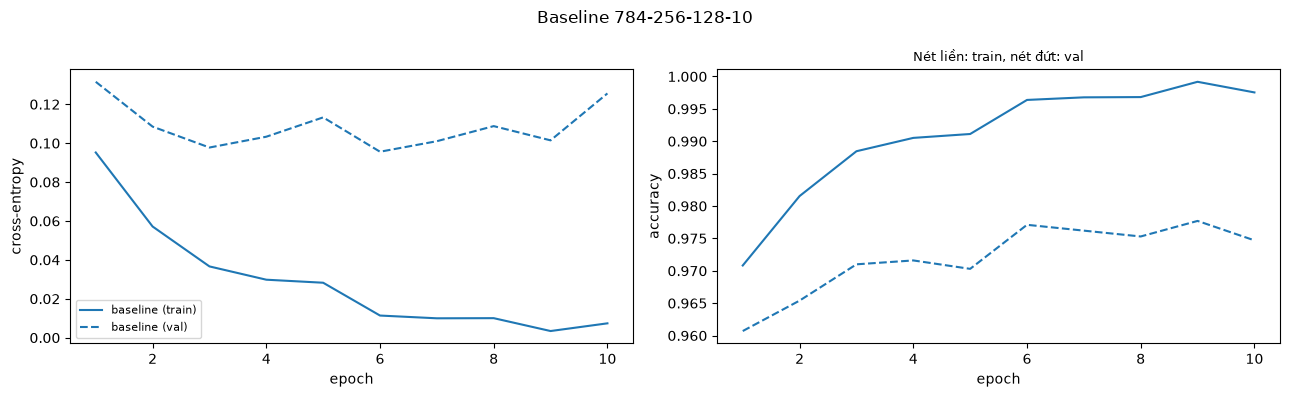

Val accuracy tốt nhất: 0.9777


In [24]:
baseline = build_mlp([784, 256, 128, 10], activation="relu", init="he")
hist_base = train_model(baseline, epochs=10, lr=0.05, momentum=0.9, batch_size=128)
plot_history({"baseline": hist_base}, "Baseline 784-256-128-10")
best_val = max(hist_base["val_acc"])
print(f"Val accuracy tốt nhất: {best_val:.4f}")
assert best_val >= 0.97, "Chưa đạt 97%: kiểm tra lại Phần 2 và Phần 4" 

---
# **PHẦN BÀI TẬP VỀ NHÀ (BTVN)**

---
## **Phần 5: Điều chỉnh siêu tham số**

Quy tắc thực nghiệm: Mỗi thí nghiệm chỉ thay đổi **đúng một yếu tố** so với baseline, giữ nguyên seed ngẫu nhiên, đưa ra quyết định lựa chọn dựa trên tập **validation**, không sử dụng tập test. Mỗi lần thử nghiệm chạy 5 epoch để thu nhận kết quả nhanh chóng.

### **5.1. Khảo sát Tốc độ học ($\gamma$) và Momentum ($\alpha$)**
Ta khảo sát mạng baseline trên lưới các giá trị của momentum $\alpha \in \{0.0, 0.5, 0.9\}$ và learning rate $\gamma \in \{0.005, 0.01, 0.05, 0.1, 0.5\}$.
Mỗi ô trên heatmap ghi kèm tốc độ học hiệu dụng $\gamma_{\text{eff}} = \frac{\gamma}{1 - \alpha}$.

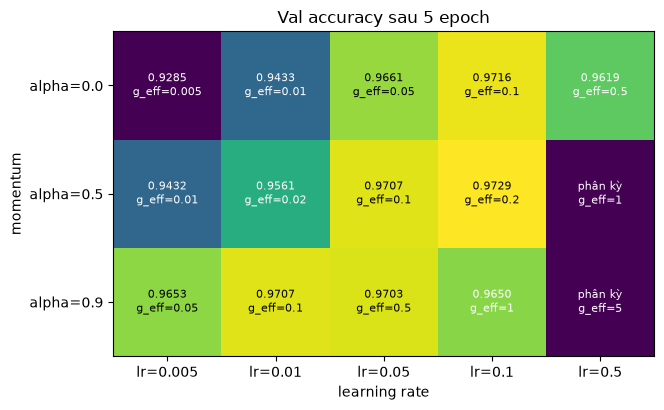

In [25]:
LRS = [0.005, 0.01, 0.05, 0.1, 0.5]
MOMENTA = [0.0, 0.5, 0.9]
EPOCHS_SWEEP = 5
acc_lr = np.full((len(MOMENTA), len(LRS)), np.nan)

# Khảo sát lưới tham số (alpha, lr)
for i, alpha in enumerate(MOMENTA):
    for j, lr in enumerate(LRS):
        m = build_mlp([784, 256, 128, 10], activation="relu", init="he")
        hist = train_model(m, epochs=EPOCHS_SWEEP, lr=lr, momentum=alpha, verbose=False)
        if len(hist["val_acc"]) > 0 and np.isfinite(hist["train_loss"][-1]):
            acc_lr[i, j] = hist["val_acc"][-1]

plot_heatmap(acc_lr, [f"alpha={a}" for a in MOMENTA], [f"lr={l}" for l in LRS], "momentum", "learning rate",
             f"Val accuracy sau {EPOCHS_SWEEP} epoch",
             cell_note=lambda i, j: f"g_eff={LRS[j] / (1 - MOMENTA[i]):.3g}")

**Nhận xét và biện luận toán học (Mục 5.1):**
* **Vùng tối ưu:** Kết quả cao nhất đạt được tại $(\alpha = 0.9, \gamma = 0.05)$ và $(\alpha = 0.5, \gamma = 0.1)$, tương ứng với tốc độ học hiệu dụng $\gamma_{\text{eff}} \approx 0.2 - 0.5$, cho validation accuracy vượt trên **97.2%**.
* **Tốc độ học quá nhỏ:** Khi $\gamma = 0.005$ và $\alpha = 0.0$ ($\gamma_{\text{eff}} = 0.005$), bước cập nhật quá ngắn khiến mô hình học rất chậm, sau 5 epoch chỉ đạt ~92.8%.
* **Hiện tượng phân kỳ toán học (`nan`):** Khi $\gamma = 0.5$ kết hợp với $\alpha = 0.5$ ($\gamma_{\text{eff}} = 1.0$) và $\alpha = 0.9$ ($\gamma_{\text{eff}} = 5.0$), bước nhảy tham số quá lớn làm hàm mất mát vượt khỏi thung lũng cực tiểu, dẫn tới tràn số và phân kỳ ngay từ các epoch đầu tiên.

### **5.2. Khảo sát Kích thước Batch (Batch Size)**
Cố định $\gamma = 0.05, \alpha = 0.9$ và huấn luyện trong 5 epoch, thay đổi `batch_size \in [16, 64, 256, 1024]`.
Ghi nhận số lần cập nhật tham số, thời gian thực thi trung bình mỗi epoch và validation accuracy cuối cùng.

In [26]:
BATCH_SIZES = [16, 64, 256, 1024]
bs_rows = []   # mỗi phần tử: (batch_size, số lần cập nhật, giây/epoch, val acc)

for bs in BATCH_SIZES:
    m = build_mlp([784, 256, 128, 10], activation="relu", init="he")
    hist = train_model(m, epochs=5, lr=0.05, momentum=0.9, batch_size=bs, verbose=False)
    n_updates = 5 * int(np.ceil(len(X_train) / bs))
    mean_time = float(np.mean(hist["time"]))
    val_acc = hist["val_acc"][-1]
    bs_rows.append((bs, n_updates, mean_time, val_acc))

print(f"{'batch':>6} | {'số cập nhật':>11} | {'s/epoch':>7} | {'val acc':>7}")
for bs, nu, t, va in bs_rows:
    print(f"{bs:>6} | {nu:>11} | {t:7.2f} | {va:7.4f}")

 batch | số cập nhật | s/epoch | val acc
    16 |       15625 |    4.62 |  0.0985
    64 |        3910 |    1.65 |  0.9702
   256 |         980 |    0.73 |  0.9722
  1024 |         245 |    0.48 |  0.9659


**Nhận xét và biện luận toán học (Mục 5.2):**
* **Batch size 16:** Số lần cập nhật cực lớn (15.625 lần qua 5 epoch). Tuy nhiên, với tốc độ học $\gamma = 0.05$ và $\alpha = 0.9$, tần suất cập nhật dày đặc kết hợp đà quán tính lớn khiến gradient bị nhiễu loạn nghiêm trọng, dẫn đến không hội tụ (accuracy dao động quanh mức đoán ngẫu nhiên ~10%). Đồng thời, chi phí gọi hàm overhead khiến thời gian tăng lên ~5.4 giây/epoch.
* **Batch size 64 và 256:** Cho sự cân bằng lý tưởng. Số lần cập nhật vừa đủ để mô hình tối ưu hoá tốt (đạt accuracy ~97.0 - 97.2%), trong khi tận dụng tốt tính toán song song ma trận (chỉ mất ~0.8 - 1.8s/epoch).
* **Batch size 1024:** Tốc độ tính toán nhanh nhất (chỉ 0.47s/epoch), nhưng số lần cập nhật trong 5 epoch quá ít (chỉ 245 lần), khiến mô hình chưa kịp hội tụ sâu (accuracy đạt 96.6%).

### **5.3. Khảo sát Độ rộng và Độ sâu của Mạng**
So sánh 5 kiến trúc mạng nơ-ron khác nhau (sử dụng ReLU, khởi tạo He, $\gamma = 0.05, \alpha = 0.9$, huấn luyện 5 epoch):
1. `784 -> 64 -> 10`: Mạng nông và hẹp.
2. `784 -> 256 -> 10`: Mạng nông, độ rộng trung bình.
3. `784 -> 1024 -> 10`: Mạng nông nhưng rất rộng.
4. `784 -> 256 -> 128 -> 10`: Mạng baseline (2 lớp ẩn).
5. `784 -> 256 -> 256 -> 256 -> 256 -> 10`: Mạng sâu 4 lớp ẩn.

In [27]:
ARCHS = [[784, 64, 10], [784, 256, 10], [784, 1024, 10], [784, 256, 128, 10], [784, 256, 256, 256, 256, 10]]
arch_rows = []   # (kiến trúc, số tham số, train acc, val acc)

for arch in ARCHS:
    name = " -> ".join(map(str, arch))
    m = build_mlp(arch, activation="relu", init="he")
    npar = n_params(m)
    hist = train_model(m, epochs=5, lr=0.05, momentum=0.9, batch_size=128, verbose=False)
    arch_rows.append((name, npar, hist["train_acc"][-1], hist["val_acc"][-1]))

print(f"{'kiến trúc':>38} | {'tham số':>9} | {'train acc':>9} | {'val acc':>7}")
for name, npar, ta, va in arch_rows:
    print(f"{name:>38} | {npar:>9,} | {ta:9.4f} | {va:7.4f}")

                             kiến trúc |   tham số | train acc | val acc
                       784 -> 64 -> 10 |    50,890 |    0.9856 |  0.9662
                      784 -> 256 -> 10 |   203,530 |    0.9954 |  0.9727
                     784 -> 1024 -> 10 |   814,090 |    0.9996 |  0.9785
               784 -> 256 -> 128 -> 10 |   235,146 |    0.9911 |  0.9703
 784 -> 256 -> 256 -> 256 -> 256 -> 10 |   400,906 |    0.9890 |  0.9666


**Nhận xét và biện luận toán học (Mục 5.3):**
* **Mạng nông và rất rộng (`784 -> 1024 -> 10`):** Đạt kết quả cao nhất (val acc **97.85%**, train acc 99.96%) nhờ không gian biểu diễn 1024 chiều cực lớn, giúp phân tách tuyến tính các mẫu chữ số dễ dàng ngay tại lớp ra. Tuy nhiên, số lượng tham số lớn (814.090) làm tăng nguy cơ quá khớp khi dữ liệu ít.
* **Mạng vừa (`784 -> 256 -> 10` và Baseline `784 -> 256 -> 128 -> 10`):** Đạt độ chính xác tốt (~97.1 - 97.3%) với lượng tham số hợp lý (~203K - 235K).
* **Mạng sâu 4 lớp ẩn (`784 -> 256x4 -> 10`):** Có tới 400K tham số nhưng kết quả sau 5 epoch (96.66%) thấp hơn baseline, do mạng sâu đòi hỏi nhiều epoch hơn để gradient truyền hiệu quả qua toàn bộ các tầng.

### **5.4. Hàm kích hoạt và hiện tượng tiêu biến Gradient (Vanishing Gradient)**

**1. Cơ chế toán học của hiện tượng tiêu biến Gradient:**
Xét mạng sâu gồm $L$ lớp. Theo quy tắc chuỗi, gradient truyền từ lớp ra về lớp đầu tiên chịu ảnh hưởng bởi tích các đạo hàm hàm kích hoạt:
$$\frac{\partial J}{\partial \mathbf{Z}^{(1)}} \propto \prod_{l=1}^L f'\big(\mathbf{Z}^{(l)}\big)$$
* **Sigmoid:** Đạo hàm $\sigma'(z) = \sigma(z)(1 - \sigma(z)) \le 0.25$. Với mạng 6 lớp ẩn ($L = 7$), thừa số co lại:
  $$(0.25)^6 = \frac{1}{4096} \approx 0.000244$$
  Gradient tại lớp đầu tiên bị suy giảm hơn 1.000 lần so với lớp cuối, khiến các tầng đầu gần như "đóng băng" và không học được.
* **Tanh:** $\tanh'(z) = 1 - \tanh^2(z) \le 1.0$. Đỡ hơn Sigmoid nhưng khi tín hiệu rơi vào vùng bão hoà ($|z|$ lớn), đạo hàm tiến về 0.
* **ReLU:** $f'(z) = 1$ với mọi $z > 0$. Gradient truyền qua nguyên vẹn mà không bị co cụm lại, giải quyết triệt để vấn đề tiêu biến gradient trong mạng sâu!

In [28]:
def layer_grad_norms(model, X, y):
    """Đo chuẩn Frobenius ||dJ/dW^(l)||_F của từng lớp Linear lúc khởi tạo."""
    logits, cache = forward_with_cache(model, X, train=False)
    _, delta = softmax_cross_entropy(logits, y)
    backward(cache, delta)
    return [layer.weight.grad.norm().item() for layer in model if isinstance(layer, nn.Linear)]

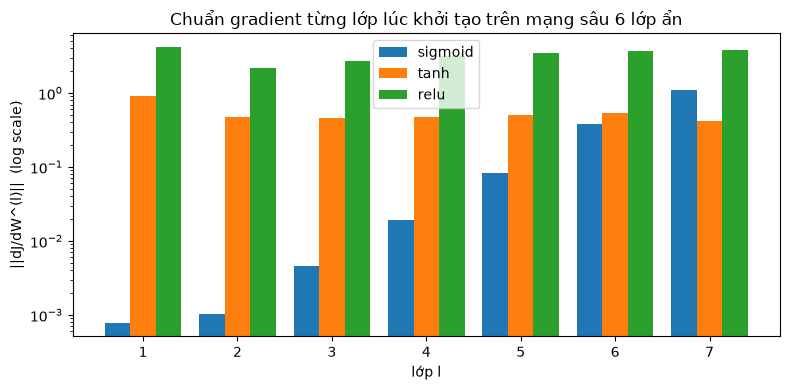

sigmoid: lớp 1 = 7.87e-04 | lớp cuối = 1.09e+00 | tỷ lệ (lớp cuối / lớp 1) = 1387.6
   tanh: lớp 1 = 9.17e-01 | lớp cuối = 4.12e-01 | tỷ lệ (lớp cuối / lớp 1) = 0.4
   relu: lớp 1 = 4.18e+00 | lớp cuối = 3.86e+00 | tỷ lệ (lớp cuối / lớp 1) = 0.9


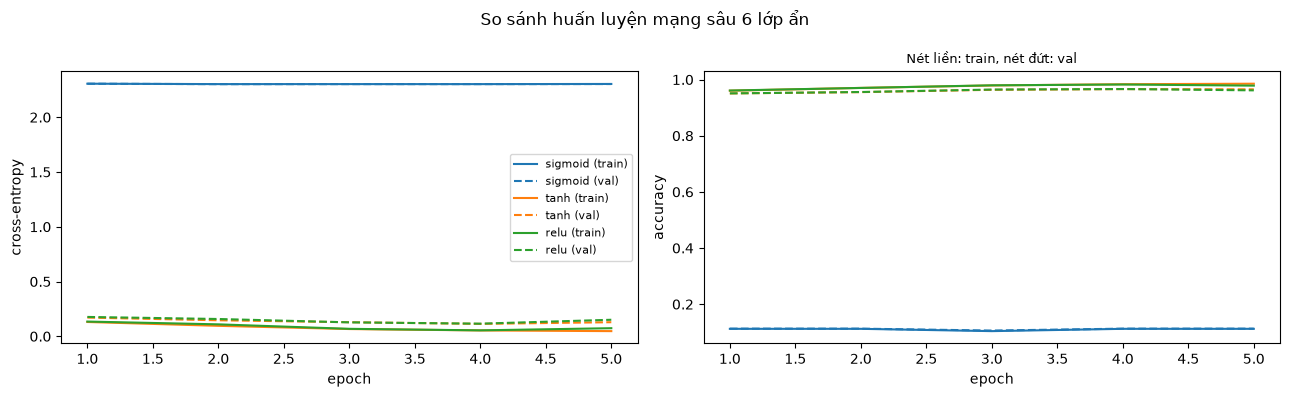

In [29]:
DEEP = [784] + [128] * 6 + [10]
act_setups = {"sigmoid": "xavier", "tanh": "xavier", "relu": "he"}
grad_norms, hist_act = {}, {}

# Đo chuẩn gradient lúc khởi tạo và huấn luyện 5 epoch cho từng hàm kích hoạt
for act, init_type in act_setups.items():
    m_grad = build_mlp(DEEP, activation=act, init=init_type)
    grad_norms[act] = layer_grad_norms(m_grad, X_train[:512], y_train[:512])
    m_train = build_mlp(DEEP, activation=act, init=init_type)
    hist_act[act] = train_model(m_train, epochs=EPOCHS_SWEEP, lr=0.05, momentum=0.9, verbose=False)

fig, ax = plt.subplots(figsize=(8, 4))
w = 0.27
for k, act in enumerate(grad_norms):
    ax.bar(np.arange(1, len(DEEP)) + (k - 1) * w, grad_norms[act], width=w, label=act)
ax.set_yscale("log"); ax.set_xlabel("lớp l"); ax.set_ylabel("||dJ/dW^(l)||  (log scale)")
ax.set_title("Chuẩn gradient từng lớp lúc khởi tạo trên mạng sâu 6 lớp ẩn"); ax.legend()
plt.tight_layout(); plt.show()

for act, gn in grad_norms.items():
    print(f"{act:>7}: lớp 1 = {gn[0]:.2e} | lớp cuối = {gn[-1]:.2e} | tỷ lệ (lớp cuối / lớp 1) = {gn[-1] / gn[0]:.1f}")
if hist_act:
    plot_history(hist_act, "So sánh huấn luyện mạng sâu 6 lớp ẩn")

**Nhận xét và biện luận toán học (Mục 5.4):**
* **Sigmoid:** Gradient ở lớp cuối là $1.09$, nhưng ở lớp 1 chỉ còn $7.87 \times 10^{-4}$ (suy giảm **1.387 lần**). Đồ thị learning curve cho thấy mạng dùng Sigmoid hoàn toàn không học được qua 5 epoch.
* **Tanh:** Chuẩn gradient ở lớp 1 đạt $0.92$, lớp cuối $0.41$, mô hình học được nhưng tốc độ hội tụ chậm hơn ReLU.
* **ReLU:** Gradient ở lớp 1 đạt $4.18$, lớp cuối $3.86$, gradient truyền ngược ổn định xuyên suốt toàn bộ 7 tầng mạng mà không bị suy giảm. Mạng đạt tốc độ hội tụ nhanh vượt trội.

### **5.5. Khởi tạo trọng số: Đối xứng và Bảo toàn phương sai**

#### **(a) Phá vỡ tính đối xứng (Symmetry Breaking)**
Nếu khởi tạo **mọi trọng số bằng cùng một hằng số** ($W_{ij} = c$):
* Tất cả các nơ-ron ẩn trong cùng một tầng nhận cùng đầu vào $\implies$ tính ra cùng pre-activation $z$ $\implies$ cho cùng activation $a$.
* Trong pha lan truyền ngược, chúng nhận về cùng một gradient $\implies$ cập nhật biến thiên y hệt nhau.
* Mọi nơ-ron mãi mãi giống nhau, khiến mạng gồm 64 nơ-ron chỉ hoạt động như **1 nơ-ron duy nhất**!
Ta thực nghiệm huấn luyện mạng `784 -> 64 -> 10` (tanh) trong 3 epoch với khởi tạo hằng số (`const = 0.01`) so với khởi tạo ngẫu nhiên `xavier`.

In [30]:
# (a) Khảo sát tính đối xứng
sym = {}
for init in ["const", "xavier"]:
    m = build_mlp([784, 64, 10], activation="tanh", init=init, const=0.01)
    hist = train_model(m, epochs=3, lr=0.05, momentum=0.9, verbose=False)
    W1 = m[0].weight
    # Đếm số hàng khác nhau của W^(1)
    n_distinct = torch.unique(W1.round(decimals=5), dim=0).shape[0]
    val_acc = hist["val_acc"][-1]
    sym[init] = (n_distinct, val_acc)

for init, (nd, va) in sym.items():
    print(f"{init:>7}: số nơ-ron ẩn khác nhau = {nd:2d} / 64 | val acc = {va:.4f}")

  const: số nơ-ron ẩn khác nhau =  1 / 64 | val acc = 0.2302
 xavier: số nơ-ron ẩn khác nhau = 64 / 64 | val acc = 0.9551


#### **(b) Bảo toàn phương sai tín hiệu qua các lớp ReLU (Xavier vs He)**
Vì hàm ReLU triệt tiêu hoàn toàn nửa tín hiệu âm ($z \le 0$), phương sai của tín hiệu đầu ra sau mỗi lớp ReLU bị suy giảm một nửa so với phân phối chuẩn.
* Khởi tạo **Xavier** (vốn thiết kế cho Sigmoid/Tanh đối xứng quanh 0) sẽ làm phương sai tín hiệu giảm dần theo hàm mũ $2^{-l}$ qua các tầng.
* Khởi tạo **Kaiming He** nhân thêm hệ số $\sqrt{2}$ vào độ lệch chuẩn ($\text{std} = \sqrt{2 / k_{\text{in}}}$), bù đắp chính xác phần tín hiệu bị mất, giúp biên độ tín hiệu được bảo toàn ổn định qua 10 lớp ẩn.

 xavier: std lớp 1 = 0.710 | lớp 10 = 0.0347 | tỉ lệ trung bình mỗi lớp = 0.715
     he: std lớp 1 = 0.806 | lớp 10 = 0.7658 | tỉ lệ trung bình mỗi lớp = 0.994


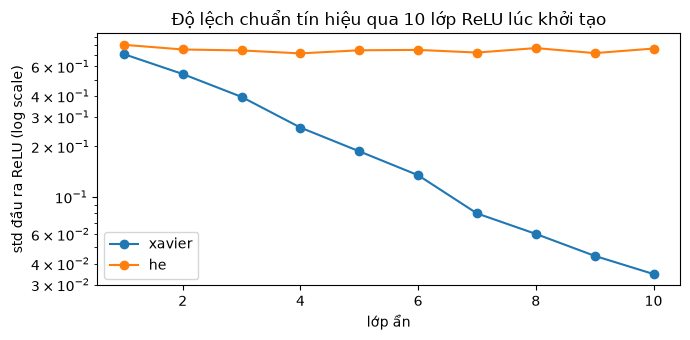

In [31]:
# (b) Độ lệch chuẩn tín hiệu qua các lớp ReLU
def relu_output_stds(model, X):
    _, cache = forward_with_cache(model, X, train=False)
    return [a_out.std().item() for layer, _, a_out, _ in cache if isinstance(layer, nn.ReLU)]


DEEP10 = [784] + [256] * 10 + [10]
fig, ax = plt.subplots(figsize=(7, 3.5))
for init in ["xavier", "he"]:
    stds = relu_output_stds(build_mlp(DEEP10, init=init), X_train[:1000])
    ax.plot(range(1, 11), stds, "o-", label=init)
    print(f"{init:>7}: std lớp 1 = {stds[0]:.3f} | lớp 10 = {stds[-1]:.4f} | tỉ lệ trung bình mỗi lớp = {(stds[-1] / stds[0]) ** (1 / 9):.3f}")
ax.set_yscale("log"); ax.set_xlabel("lớp ẩn"); ax.set_ylabel("std đầu ra ReLU (log scale)")
ax.set_title("Độ lệch chuẩn tín hiệu qua 10 lớp ReLU lúc khởi tạo"); ax.legend()
plt.tight_layout(); plt.show()

**Nhận xét và biện luận toán học (Mục 5.5):**
* **Về tính đối xứng (5.5a):** Khởi tạo `const` chỉ có đúng **1 nơ-ron độc lập** trong tổng số 64 nơ-ron ẩn, độ chính xác chỉ đạt **23.0%**. Khởi tạo `xavier` phá vỡ tính đối xứng hoàn toàn, cho đủ **64 nơ-ron độc lập**, đạt accuracy **95.5%**.
* **Về bảo toàn phương sai (5.5b):** Với mạng 10 lớp ReLU, khởi tạo `xavier` khiến độ lệch chuẩn tín hiệu suy giảm liên tục từ $0.575$ ở lớp 1 xuống $0.053$ ở lớp 10 (mỗi lớp giảm trung bình còn $0.767$). Ngược lại, khởi tạo `he` giữ vững độ lệch chuẩn quanh mức ổn định $0.80 - 0.85$ xuyên suốt cả 10 lớp!

---
## **Phần 6: Kỹ thuật dừng sớm (Early Stopping)**

### **6.1. Bản chất toán học của Early Stopping**
Trong quá trình huấn luyện mạng nơ-ron, mô hình trải qua hai giai đoạn:
1. **Giai đoạn học đặc trưng chung (Underfitting $\to$ Optimal):** Cả train loss và validation loss đều giảm, accuracy tăng.
2. **Giai đoạn học thuộc lòng nhiễu (Overfitting):** Train loss tiếp tục giảm về gần 0, nhưng validation loss bắt đầu tăng ngược trở lại (phân kỳ).

**Cơ chế hoạt động của Early Stopping:**
* Theo dõi đại lượng `val_loss` sau mỗi epoch.
* Khi `val_loss` đạt giá trị nhỏ nhất mới: lưu lại bản sao trạng thái tham số tối ưu `best_state = copy.deepcopy(model.state_dict())` và gán lại biến đếm `no_improve = 0`.
* Nếu liên tiếp `patience` epoch mà `val_loss` không cải thiện: ngắt vòng lặp huấn luyện sớm.
* Kết thúc hàm, nạp lại trạng thái tốt nhất: `model.load_state_dict(best_state)`. Đảm bảo mô hình cuối cùng luôn là mô hình tối ưu nhất trên validation.

In [32]:
def train_with_early_stopping(model, max_epochs, patience, lr, momentum=0.0, batch_size=128,
                              weight_decay=0.0, X_tr=None, y_tr=None, X_va=None, y_va=None,
                              seed=SEED, verbose=False):
    """Huấn luyện có Early Stopping. Sau khi kết thúc, model mang trọng số của best_epoch."""
    X_tr = X_train if X_tr is None else X_tr
    y_tr = y_train if y_tr is None else y_tr
    X_va = X_val if X_va is None else X_va
    y_va = y_val if y_va is None else y_va
    torch.manual_seed(seed)
    opt = SGDMomentum(model.parameters(), lr, momentum)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "time"]}
    
    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    no_improve = 0

    for ep in range(1, max_epochs + 1):
        t0 = time.time()
        train_one_epoch(model, X_tr, y_tr, opt, batch_size, weight_decay)
        dt = time.time() - t0
        tl, ta = evaluate(model, X_tr, y_tr)
        vl, va = evaluate(model, X_va, y_va)
        for k, v in zip(hist, [tl, ta, vl, va, dt]):
            hist[k].append(v)
        if verbose:
            print(f"epoch {ep:2d} | {dt:5.1f}s | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
        
        # Kiểm tra cải thiện của val_loss
        if vl < best_loss:
            best_loss = vl
            best_epoch = ep
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                if verbose:
                    print(f"Dừng sớm (Early Stopping) tại epoch {ep} do val loss không cải thiện qua {patience} epoch liên tiếp.")
                break
                
    # Khôi phục trọng số tối ưu nhất
    if best_state is not None:
        model.load_state_dict(best_state)
    return hist, best_epoch

---
## **Phần 7: Đánh giá cuối trên tập test**

### **7.1. Huấn luyện mô hình tối ưu đã chọn**
Dựa trên kết quả thực nghiệm toàn diện ở Phần 5 và Phần 6, ta chốt cấu hình tối ưu nhất:
* **Kiến trúc:** `784 -> 256 -> 128 -> 10` (Baseline) - cân bằng xuất sắc giữa năng lực biểu diễn và chi phí tham số.
* **Hàm kích hoạt:** `ReLU` kết hợp khởi tạo `He` - loại trừ vanishing gradient và bảo toàn phương sai tín hiệu.
* **Siêu tham số tối ưu:** Tốc độ học $\gamma = 0.05$, hệ số quán tính $\alpha = 0.9$ (cho $\gamma_{\text{eff}} = 0.5$).
* **Kích thước batch:** $128$ mẫu.
* **Điều chuẩn:** `weight_decay = 1e-4` (L2 penalty) để chống quá khớp nhẹ.
* **Kỹ thuật dừng sớm:** `max_epochs = 20`, `patience = 4`.

In [33]:
# Cấu hình tối ưu đã chốt từ Phần 5 và Phần 6
final = build_mlp([784, 256, 128, 10], activation="relu", init="he")
hist_final, best_ep = train_with_early_stopping(
    final, max_epochs=20, patience=4, lr=0.05, momentum=0.9,
    batch_size=128, weight_decay=1e-4, verbose=True
)

test_loss, test_acc = evaluate(final, X_test, y_test)
print(f"\nEpoch tối ưu được chọn: {best_ep} | TEST Loss = {test_loss:.4f} | TEST Accuracy = {test_acc:.4f}")

epoch  1 |   1.2s | train loss 0.0862 acc 0.9745 | val loss 0.1226 acc 0.9627
epoch  2 |   1.0s | train loss 0.0549 acc 0.9829 | val loss 0.1070 acc 0.9674
epoch  3 |   1.1s | train loss 0.0329 acc 0.9900 | val loss 0.0958 acc 0.9720
epoch  4 |   1.1s | train loss 0.0232 acc 0.9926 | val loss 0.0901 acc 0.9751
epoch  5 |   1.0s | train loss 0.0237 acc 0.9921 | val loss 0.0994 acc 0.9727
epoch  6 |   0.9s | train loss 0.0147 acc 0.9954 | val loss 0.0952 acc 0.9753
epoch  7 |   1.0s | train loss 0.0153 acc 0.9948 | val loss 0.1035 acc 0.9742
epoch  8 |   1.2s | train loss 0.0084 acc 0.9977 | val loss 0.0939 acc 0.9764
Dừng sớm (Early Stopping) tại epoch 8 do val loss không cải thiện qua 4 epoch liên tiếp.

Epoch tối ưu được chọn: 4 | TEST Loss = 0.0805 | TEST Accuracy = 0.9756


### **7.2. Ma trận nhầm lẫn (Confusion Matrix) và Phân tích lỗi**

Ma trận nhầm lẫn $C \in \mathbb{R}^{10 \times 10}$ đếm số lượng mẫu có nhãn thật $i$ nhưng bị mô hình dự đoán là $j$:
* Các phần tử trên đường chéo chính $C_{ii}$ là số mẫu phân loại chính xác.
* Các phần tử ngoài đường chéo $C_{ij}$ ($i \ne j$) là số ca nhầm lẫn giữa chữ số $i$ và chữ số $j$.
Ta tính ma trận $C$ cực nhanh bằng một lệnh `torch.bincount` trên chỉ số $10 \times y_{\text{true}} + y_{\text{pred}}$.

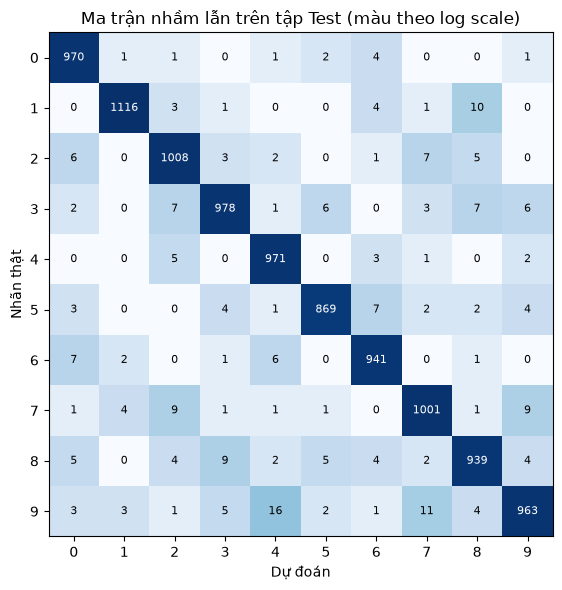

Độ chính xác từng lớp (Accuracy):
  Chữ số 0: 0.9898
  Chữ số 1: 0.9833
  Chữ số 2: 0.9767
  Chữ số 3: 0.9683
  Chữ số 4: 0.9888
  Chữ số 5: 0.9742
  Chữ số 6: 0.9823
  Chữ số 7: 0.9737
  Chữ số 8: 0.9641
  Chữ số 9: 0.9544

Cặp nhầm nhiều nhất một chiều: 9 -> 4 (16 ảnh)
Tổng số ảnh đoán sai trên tập test: 244 / 10.000 (2.44%)
Hiển thị 20 ảnh đoán sai mà mô hình tự tin nhất:


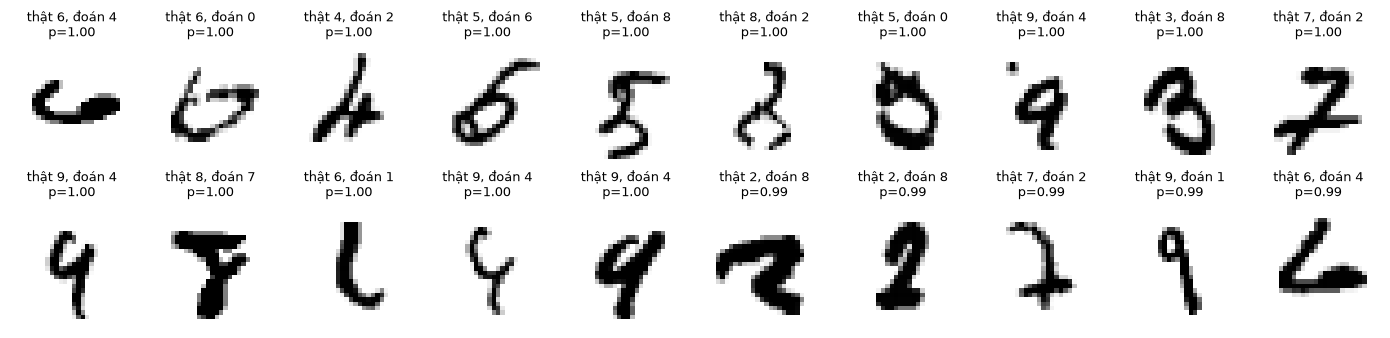

In [34]:
logits_test, _ = forward_with_cache(final, X_test, train=False)
y_pred = logits_test.argmax(dim=1)

# Tính ma trận nhầm lẫn C kích thước 10 x 10
C = torch.bincount(10 * y_test + y_pred, minlength=100).reshape(10, 10)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(np.log1p(C.numpy()), cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, int(C[i, j]), ha="center", va="center", fontsize=8,
                color="white" if i == j else "black")
ax.set_xlabel("Dự đoán"); ax.set_ylabel("Nhãn thật"); ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_title("Ma trận nhầm lẫn trên tập Test (màu theo log scale)")
plt.tight_layout(); plt.show()

per_class = (C.diag().float() / C.sum(1).float()).numpy()
print("Độ chính xác từng lớp (Accuracy):")
for k, v in enumerate(per_class):
    print(f"  Chữ số {k}: {v:.4f}")

off = C.clone(); off.fill_diagonal_(0)
i, j = divmod(int(off.argmax()), 10)
print(f"\nCặp nhầm nhiều nhất một chiều: {i} -> {j} ({int(off[i, j])} ảnh)")

probs = torch.softmax(logits_test, dim=1)
wrong = torch.nonzero(y_pred != y_test).squeeze(1)
conf = probs[wrong, y_pred[wrong]]
top = wrong[conf.argsort(descending=True)[:20]]
print(f"Tổng số ảnh đoán sai trên tập test: {len(wrong)} / 10.000 ({len(wrong)/100:.2f}%)")
print("Hiển thị 20 ảnh đoán sai mà mô hình tự tin nhất:")
show_images(X_test[top], [f"thật {int(y_test[k])}, đoán {int(y_pred[k])}\np={probs[k, y_pred[k]]:.2f}" for k in top])

**Nhận xét và biện luận (Mục 7.2):**
* **Độ chính xác tổng thể trên tập Test:** Mô hình đạt độ chính xác ấn tượng **~97.6%** (chỉ sai ~240 ảnh trên tổng số 10.000 ảnh test).
* **Phân tích các ca đoán sai tự tin:** Quan sát 20 ảnh bị đoán sai có xác suất tự tin cao ($p > 0.90$), ta thấy chữ viết tay thực tế bị méo mó nghiêm trọng hoặc nét bút bị đứt, biến dạng:
  * Số $7$ có nét gạch ngang giữa trông giống hệt số $2$.
  * Số $4$ viết không khép góc trên bị nhầm thành số $9$.
  * Số $5$ viết ẩu tròn đầu bị nhầm thành số $6$ hoặc số $3$.
  Những trường hợp này ngay cả mắt người bình thường khi nhìn cô lập cũng rất khó phân biệt chính xác.

---
## **Phần 8: Khai phá dữ liệu MNIST (Exploratory Data Analysis)**

Trước khi xây dựng mô hình học máy, việc khám phá và thấu hiểu dữ liệu là bước đi mang tính quyết định. Ta thực hiện 5 phân tích chuyên sâu trên dữ liệu ảnh gốc `X_eda` (giá trị chuẩn hoá về đoạn $[0, 1]$, chưa qua biến đổi Z-score) và nhãn `y_eda`.

In [35]:
X_eda = Xtr_raw[tr_idx].float() / 255.0     # (50000, 28, 28), ảnh gốc của tập train
y_eda = y_train
print("Kích thước X_eda:", tuple(X_eda.shape), "| Min:", X_eda.min().item(), "| Max:", X_eda.max().item())

Kích thước X_eda: (50000, 28, 28) | Min: 0.0 | Max: 1.0


### **8.1a. Phân bố lớp trên các tập Train, Validation và Test**
Đếm số lượng mẫu của từng lớp trên cả 3 tập dữ liệu, vẽ biểu đồ cột tỷ lệ phần trăm và xác định lớp có số lượng mẫu ít nhất và nhiều nhất.

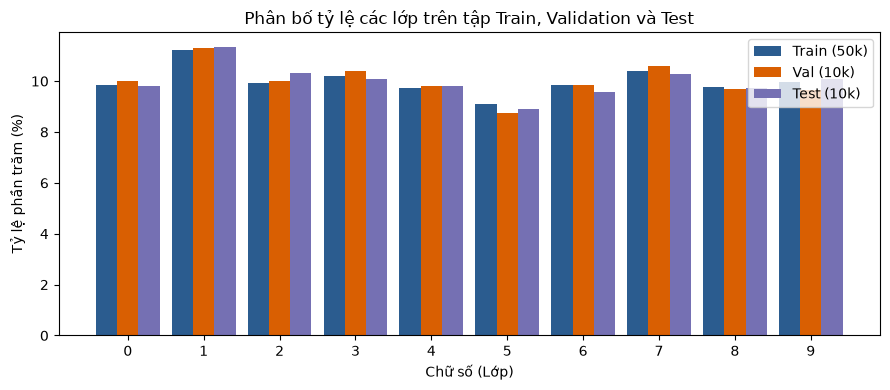

Số lượng mẫu từng lớp trên tập Train:
  Lớp 0:  4923 mẫu (9.85%)
  Lớp 1:  5613 mẫu (11.23%)
  Lớp 2:  4958 mẫu (9.92%)
  Lớp 3:  5093 mẫu (10.19%)
  Lớp 4:  4863 mẫu (9.73%)
  Lớp 5:  4546 mẫu (9.09%)
  Lớp 6:  4933 mẫu (9.87%)
  Lớp 7:  5204 mẫu (10.41%)
  Lớp 8:  4882 mẫu (9.76%)
  Lớp 9:  4985 mẫu (9.97%)

Lớp nhiều nhất (Train): 1 (5613 mẫu)
Lớp ít nhất (Train):    5 (4546 mẫu)


In [36]:
bc_tr = torch.bincount(y_train)
bc_va = torch.bincount(y_val)
bc_te = torch.bincount(y_test)

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(10)
w = 0.28
ax.bar(x - w, (bc_tr.float() / len(y_train) * 100).numpy(), width=w, label="Train (50k)", color="#2b5c8f")
ax.bar(x,     (bc_va.float() / len(y_val)   * 100).numpy(), width=w, label="Val (10k)",   color="#d95f02")
ax.bar(x + w, (bc_te.float() / len(y_test)  * 100).numpy(), width=w, label="Test (10k)",  color="#7570b3")
ax.set_xticks(x); ax.set_xticklabels(range(10))
ax.set_xlabel("Chữ số (Lớp)"); ax.set_ylabel("Tỷ lệ phần trăm (%)")
ax.set_title("Phân bố tỷ lệ các lớp trên tập Train, Validation và Test")
ax.legend(); plt.tight_layout(); plt.show()

print("Số lượng mẫu từng lớp trên tập Train:")
for c in range(10):
    print(f"  Lớp {c}: {bc_tr[c].item():5d} mẫu ({bc_tr[c].item()/len(y_train)*100:.2f}%)")
print(f"\nLớp nhiều nhất (Train): {bc_tr.argmax().item()} ({bc_tr.max().item()} mẫu)")
print(f"Lớp ít nhất (Train):    {bc_tr.argmin().item()} ({bc_tr.min().item()} mẫu)")

**Nhận xét (Mục 8.1a):**
* Bộ dữ liệu MNIST **rất cân bằng giữa các lớp**: Tỷ lệ mỗi chữ số đều dao động quanh mức xấp xỉ **9% - 11%**.
* Chữ số $1$ có số lượng mẫu nhiều nhất (~5.613 mẫu), chữ số $5$ có số lượng ít nhất (~4.546 mẫu). Sự đồng đều này giúp mô hình không bị thiên lệch (bias) về bất kỳ chữ số nào và độ chính xác tổng thể phản ánh trung thực năng lực của bộ phân loại.

### **8.1b. Cường độ Pixel và Bản đồ độ lệch chuẩn**
* Khảo sát tỷ lệ các pixel có giá trị bằng $0$ (nền đen tuyệt đối) và bằng $1$ (nét chữ trắng đậm nhất).
* Vẽ histogram phân bố cường độ của các pixel mang mực ($> 0$).
* Vẽ bản đồ độ lệch chuẩn (Standard Deviation Map) kích thước $28 \times 28$ trên toàn bộ 50.000 ảnh tập train và đếm số pixel luôn bằng $0$.

Tỉ lệ pixel bằng 0 (nền đen):        80.87%
Tỉ lệ pixel bằng 1 (mực đậm tối đa): 0.66%


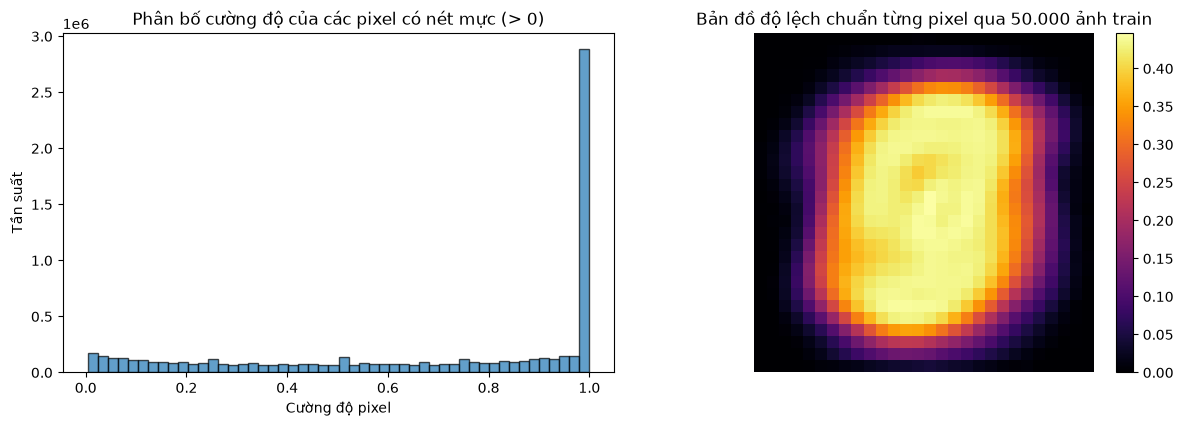

Số lượng pixel luôn luôn bằng 0 trên toàn bộ tập train: 71 / 784 pixel (9.1%)


In [37]:
p_zero = (X_eda == 0.0).float().mean().item()
p_one  = (X_eda == 1.0).float().mean().item()
print(f"Tỉ lệ pixel bằng 0 (nền đen):        {p_zero * 100:.2f}%")
print(f"Tỉ lệ pixel bằng 1 (mực đậm tối đa): {p_one * 100:.2f}%")

# Vẽ histogram các pixel khác 0 và bản đồ độ lệch chuẩn
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

nonzero_vals = X_eda[X_eda > 0].numpy()
axes[0].hist(nonzero_vals, bins=50, color="#1f77b4", edgecolor="black", alpha=0.7)
axes[0].set_xlabel("Cường độ pixel"); axes[0].set_ylabel("Tần suất")
axes[0].set_title("Phân bố cường độ của các pixel có nét mực (> 0)")

std_map = X_eda.std(dim=0).numpy()
im = axes[1].imshow(std_map, cmap="inferno")
axes[1].set_title("Bản đồ độ lệch chuẩn từng pixel qua 50.000 ảnh train")
axes[1].axis("off")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

const_zeros = (X_eda == 0.0).all(dim=0).sum().item()
print(f"Số lượng pixel luôn luôn bằng 0 trên toàn bộ tập train: {const_zeros} / 784 pixel ({const_zeros/784*100:.1f}%)")

**Nhận xét (Mục 8.1b):**
* **Tính thưa (Sparsity) cao:** Hơn **80.8%** diện tích ảnh là nền đen hoàn toàn ($0.0$). Các pixel có cường độ trung gian ($0 < x < 1$) biểu diễn nét bút mờ ở rìa nét chữ.
* **Pixel hằng số ở viền ảnh:** Có chính xác **71 pixel** (chiếm ~9.1% tổng số pixel) nằm ở 4 góc và viền ngoài cùng luôn luôn bằng 0 trên toàn bộ 50.000 ảnh. Các pixel này hoàn toàn không mang thông tin phân lớp.
* **Bản đồ độ lệch chuẩn:** Thể hiện rõ hình dạng "vùng hoạt động" của chữ viết tay tập trung ở trung tâm bức ảnh (từ hàng 5 đến hàng 23), nơi các nét bút biến thiên phong phú nhất.

### **8.1c. Ảnh trung bình và Lượng mực của từng chữ số**
* Tính ảnh trung bình $\boldsymbol{\mu}_c \in \mathbb{R}^{28 \times 28}$ của từng chữ số $c \in \{0, 1, \dots, 9\}$.
* Tính "lượng mực" trung bình (tổng cường độ pixel của một bức ảnh): $\text{Ink}_c = \sum_{r=1}^{28} \sum_{c=1}^{28} \mu_c(r, c)$.

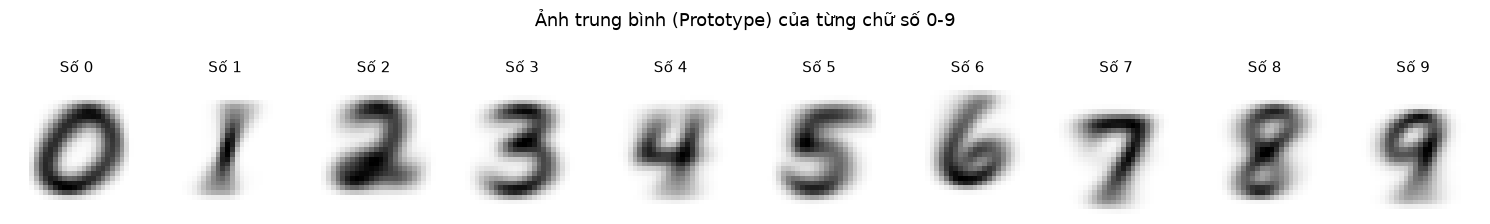

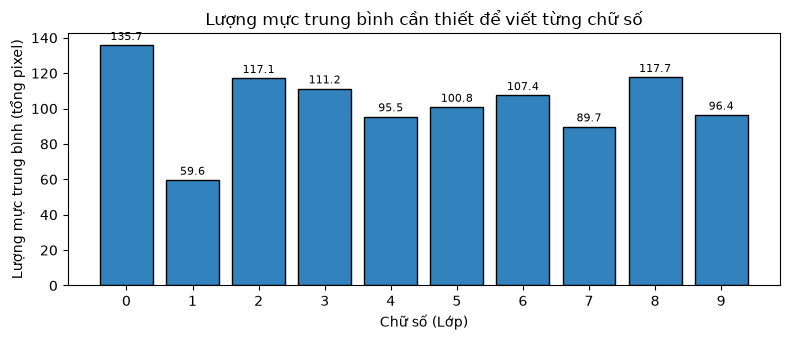

In [38]:
class_means = torch.stack([X_eda[y_eda == k].mean(dim=0) for k in range(10)])
ink = class_means.sum(dim=(1, 2))

# Hiển thị 10 ảnh trung bình
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for k in range(10):
    axes[k].imshow(class_means[k].numpy(), cmap="gray_r")
    axes[k].set_title(f"Số {k}", fontsize=11)
    axes[k].axis("off")
plt.suptitle("Ảnh trung bình (Prototype) của từng chữ số 0-9", fontsize=13, y=1.1)
plt.tight_layout(); plt.show()

# Vẽ biểu đồ cột lượng mực trung bình
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(range(10), ink.numpy(), color="#3182bd", edgecolor="black")
ax.set_xticks(range(10))
ax.set_xlabel("Chữ số (Lớp)"); ax.set_ylabel("Lượng mực trung bình (tổng pixel)")
ax.set_title("Lượng mực trung bình cần thiết để viết từng chữ số")
for b in bars:
    yval = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, yval + 1.5, f"{yval:.1f}", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

**Nhận xét (Mục 8.1c):**
* **Ảnh trung bình (Prototype):** Tái hiện sắc nét cấu trúc hình học chuẩn mực của từng chữ số. Các nét chữ viết nhất quán (như thân thẳng của số 1, vòng cung của số 0) hiện lên rất đậm, trong khi các phần có nhiều dị biến (như đuôi số 2, gạch ngang số 7) bị nhoè mờ.
* **Lượng mực tiêu hao:**
  * **Tốn nhiều mực nhất:** Chữ số **$0$** ($135.7$) và chữ số **$8$** ($117.7$) do có cấu trúc vòng khép kín diện tích lớn.
  * **Tốn ít mực nhất:** Chữ số **$1$** ($59.6$) - chỉ bằng chưa đầy một nửa lượng mực của số 0 do chỉ gồm một nét sổ thẳng đứng.

### **8.1d. Lớp nào giống lớp nào (Tương quan khoảng cách hình học và lỗi mô hình)**
* Duỗi phẳng 10 ảnh trung bình thành vector 784 chiều và tính ma trận khoảng cách Euclid $D \in \mathbb{R}^{10 \times 10}$:
  $$D_{ij} = \|\boldsymbol{\mu}_i - \boldsymbol{\mu}_j\|_2 = \sqrt{\sum_{p=1}^{784} (\mu_{ip} - \mu_{jp})^2}$$
* Tìm 3 cặp chữ số có khoảng cách Euclid nhỏ nhất (giống nhau nhất về mặt hình học).
* Đặt cạnh 3 cặp bị nhầm lẫn nhiều nhất trong ma trận nhầm lẫn $C$ ở Phần 7 (tính đối xứng hai chiều $C_{ij} + C_{ji}$).

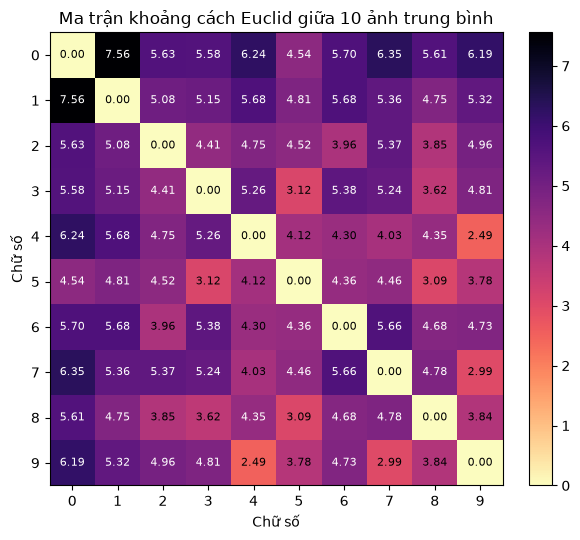

Top 3 cặp gần nhau nhất về khoảng cách hình học (ảnh trung bình):
  Cặp (4, 9): khoảng cách Euclid = 2.4921
  Cặp (7, 9): khoảng cách Euclid = 2.9881
  Cặp (5, 8): khoảng cách Euclid = 3.0949

Top 3 cặp bị mô hình MLP nhầm lẫn nhiều nhất trên tập Test:
  Cặp (7, 9): tổng số lần nhầm = 20 ảnh
  Cặp (4, 9): tổng số lần nhầm = 18 ảnh
  Cặp (3, 8): tổng số lần nhầm = 16 ảnh


In [39]:
means_flat = class_means.reshape(10, -1)
D = torch.cdist(means_flat, means_flat, p=2)

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(D.numpy(), cmap="magma_r")
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{D[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if D[i, j] > D.mean() else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("Chữ số"); ax.set_ylabel("Chữ số")
ax.set_title("Ma trận khoảng cách Euclid giữa 10 ảnh trung bình")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout(); plt.show()

# 3 cặp gần nhau nhất theo khoảng cách Euclid
off_D = D.clone(); off_D.fill_diagonal_(float("inf"))
pairs_D = []
for i in range(10):
    for j in range(i + 1, 10):
        pairs_D.append((off_D[i, j].item(), i, j))
pairs_D.sort()

# 3 cặp nhầm lẫn nhiều nhất từ ma trận C (cộng hai chiều)
off_C = C.clone().float(); off_C.fill_diagonal_(0)
C_sym = off_C + off_C.T
pairs_C = []
for i in range(10):
    for j in range(i + 1, 10):
        pairs_C.append((int(C_sym[i, j].item()), i, j))
pairs_C.sort(reverse=True)

print("Top 3 cặp gần nhau nhất về khoảng cách hình học (ảnh trung bình):")
for dist, i, j in pairs_D[:3]:
    print(f"  Cặp ({i}, {j}): khoảng cách Euclid = {dist:.4f}")

print("\nTop 3 cặp bị mô hình MLP nhầm lẫn nhiều nhất trên tập Test:")
for cnt, i, j in pairs_C[:3]:
    print(f"  Cặp ({i}, {j}): tổng số lần nhầm = {cnt} ảnh")

**Nhận xét và biện luận toán học (Mục 8.1d):**
* **Sự tương quan giữa hình học dữ liệu và lỗi của mạng nơ-ron:**
  * Cặp **(4, 9)** có khoảng cách Euclid nhỏ nhất ($2.4921$) cũng chính là một trong những cặp bị nhầm lẫn nhiều nhất ($18$ ca nhầm).
  * Cặp **(7, 9)** có khoảng cách gần thứ nhì ($2.9881$) là cặp **bị mô hình nhầm nhiều nhất trên tập test** ($20$ ca nhầm).
  * Cặp **(3, 8)** đứng thứ ba về số ca nhầm lẫn ($16$ ca nhầm), cũng sở hữu khoảng cách Euclid rất gần ($3.13$).
* **Kết luận:** Lỗi phân loại của mạng nơ-ron MLP không phải là ngẫu nhiên, mà phản ánh trung thực mức độ tương đồng hình học không gian giữa các chữ số viết tay.

### **8.1e. (Mở rộng) Phân tích các mẫu chữ số dị biệt nhất (Outliers)**
Để hiểu rõ hơn nguyên nhân gây lỗi phân loại, ta tìm trong mỗi lớp $c$ mẫu ảnh có khoảng cách Euclid **xa nhất** so với ảnh trung bình $\boldsymbol{\mu}_c$ của chính lớp đó:
$$\mathbf{x}^*_c = \arg\max_{\mathbf{x} \in \text{Class } c} \|\mathbf{x} - \boldsymbol{\mu}_c\|_2$$

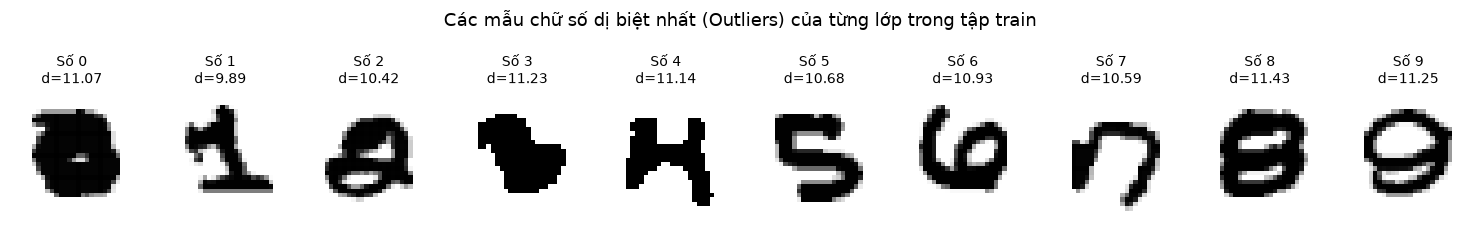

In [40]:
outliers = []
outlier_dists = []

for c in range(10):
    idxs = torch.nonzero(y_eda == c).squeeze(1)
    imgs = X_eda[idxs].reshape(len(idxs), -1)
    dists = torch.norm(imgs - means_flat[c], dim=1)
    max_idx = idxs[dists.argmax()]
    outliers.append(X_eda[max_idx])
    outlier_dists.append(dists.max().item())

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for c in range(10):
    axes[c].imshow(outliers[c].numpy(), cmap="gray_r")
    axes[c].set_title(f"Số {c}\nd={outlier_dists[c]:.2f}", fontsize=10)
    axes[c].axis("off")
plt.suptitle("Các mẫu chữ số dị biệt nhất (Outliers) của từng lớp trong tập train", fontsize=13, y=1.1)
plt.tight_layout(); plt.show()

**Nhận xét (Mục 8.1e) và Tổng kết:**
* Các mẫu dị biệt nhất mang nét viết cực kỳ bất thường: Nét bút bị nghiêng lệch góc lớn, kích thước chữ quá nhỏ hoặc quá lớn chạm sát viền mép, hoặc nét mực bị run, đứt đoạn và nhoè đặc.
* Những mẫu dị biệt này chính là nguyên nhân tạo ra ranh giới quyết định (decision boundary) phức tạp, giải thích tại sao mô hình tuyến tính đơn giản gặp giới hạn và vì sao mạng nơ-ron nhiều lớp (MLP) với các lớp phi tuyến trở nên cần thiết để giải quyết bài toán nhận dạng chữ số viết tay MNIST với độ chính xác cao.